# Westline Carriers — what is actually happening with the tyres?

**Data:** TyreSense TPMS exports (6 trucks × 1 Jun–15 Jul 2026), tyre register, tread-depth (NSD) sheets, daily odometer log, inflation standard, one interview with the fleet manager.

**How to read this notebook.** Each section states the question, the physical reasoning *before* any statistics, what was done, what was found, how confident I am, and what would change my mind. Section 0 is the summary; everything after it is the evidence. All numbers in the text were checked against the cell outputs.

**Naming.** The manager thinks in runs, not registrations, so I use both:

| Fleet | Registration | Run | Depot |
|---|---|---|---|
| T1 | KA25AB4471 | Goa (via Anmod ghat) | Belagavi |
| T2 | KA25AC1182 | Karwar | Belagavi |
| T3 | KA22AD7730 | Gadag distribution | Hubballi |
| T4 | KA25AE2016 | Hubballi city | Hubballi |
| T5 | KA48AF9054 | Shivamogga (+ one Mangaluru run) | Hubballi |
| T6 | KA22AG3391 | Vijayapura | Belagavi |

## 0. Summary — what is actually happening with Westline's tyres

**One sentence.** The tyres are mostly fine; the *alarms* are mostly physics and procedure, the one real failure was visible for almost nine hours, and three Hubballi trucks are being run 7–10% under-inflated by the depot's own routine.

| # | Finding | Where | Confidence | What would change my mind |
|---|---|---|---|---|
| 1 | **Hubballi trucks (T3, T4, T5) run ~7–10% under the cold standard** because the depot fills (and sometimes *releases* air) on hot tyres in the afternoon to the card number. On 4–5 Jun, T4 and T3 were bled down to ~14–17 PSI under standard when cold. Belagavi fills cold at 06:00 and sits on the card. **Not leakage:** leak rates are equal at both depots. | §4 | High | A depot log showing fills were cold; TPMS reading low only in the afternoon |
| 2 | **The Karwar failure (T2 inner tyre 5RI, 11 Jul) was not a slow leak, but it was visible for 8 h 56 min before the truck stopped.** It tracked its twin for six weeks, then began losing 6–8 PSI/h at ~03:15, minutes after leaving the yard. A relative-pressure alert would have fired at ~03:25–03:40; the raw "90% of card" line was crossed at 06:25. **Not foreseeable days ahead; avoidable with an alert that reaches the driver.** | §5 | High on timeline; low on cause | A second failure with a slow precursor; the removed casing's report |
| 3 | **"Fourteen alarms every afternoon" is temperature, not tyres.** Sensor pressure moves ~0.71 PSI per reported °C (≈1.9× the gas law), about 14 PSI a day on a typical tyre; the common cooling events hit 4–6 trucks in the same 20 minutes (consistent with rain), plus a daily post-descent cool-down on Goa. A *rapid-fall* rule on raw PSI reproduces the pattern (Goa: 12 afternoons with ≥10 tyres alarming together). | §2–3 | High (thermal); moderate (rain) | Weather records; vendor's actual alert rules |
| 4 | **A short, real watch-list:** T1 4LI and T3 5RO lose ~10 PSI/month more than their truck-mates and have fast-draining, drop-prone sensors; T2 3LO has the sensor signature and ~5 PSI/month excess; T5 2RO's sensor is at 1% battery. | §6 | Moderate–high | Soap test showing valves/beads sound |
| 5 | **Sensor batteries drain ~0.29 pts/day (~1 year to empty at that rate)** vs the vendor's "3–4 years"; six weeks cannot establish a discharge curve. | §6 | Low–moderate | Vendor's discharge curve |
| 6 | **Left tyres wear faster than right on every inspected axle (20/20, median 2.6 mm); on T1 about 2× faster.** Whether **Hubballi roads** eat tyres **cannot be answered** from the pack. | §8 | High (L/R); none (roads) | A second inspection of T3/T4 after ≥5,000 km |
| 7 | **Sources:** the odometer log is reliable; the depot gauge and TPMS agree within ~1 PSI; the Data Dictionary has C/D reversed; the register overwrote the failed tyre; the rotation was on the Goa truck, not Karwar; the exports overlap and one has a mistyped registration. | §1, §10, §13 | High | — |
| 8 | **Ghat:** Goa's drive-axle tyres reach 67–71 °C on every descent with no trend over six weeks; the pack cannot say anything about brake condition. | §9 | Moderate | Speed/altitude channels from TyreSense |

**First actions I would recommend** (ordered by cost and by what the evidence is strongest on): (1) make the Hubballi routine **cold-fill only** — before the first run or after ≥3 h parked — and re-check T3, T4, T5 tomorrow morning; (2) get TyreSense to send **per-tyre relative-pressure alerts to the driver's phone** (and document the alert rules); (3) inspect **T1 4LI, T3 5RO, T2 3LO** (valve, bead, sensor seal) and replace the **T5 2RO** sensor; (4) book the **second tread inspection** for T3/T4 and a first for T5/T6.

**Scope honesty.** Six weeks, one failure, no load, weather, speed or alert-rule data. The detector in §7 is a design with one confirming case, not a validated model.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 95, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

DATA = Path.cwd()                      # notebook sits in the candidate-pack folder
FLEET = pd.DataFrame([
    ("T1","KA25AB4471","Goa","Belagavi"),   ("T2","KA25AC1182","Karwar","Belagavi"),
    ("T3","KA22AD7730","Gadag","Hubballi"), ("T4","KA25AE2016","City","Hubballi"),
    ("T5","KA48AF9054","Shivamogga","Hubballi"), ("T6","KA22AG3391","Vijayapura","Belagavi")],
    columns=["fleet","veh","run","depot"]).set_index("veh")
NAME  = {v: f"{r.fleet} {r.run}" for v, r in FLEET.iterrows()}
DEPOT = FLEET.depot.to_dict()
SLOTS = ['1LO','1RO','2LO','2RO','3LO','3RO','4LI','4LO','4RI','4RO','5LI','5LO','5RI','5RO']
SPEC  = {"1":115, "2":105, "3":105, "4":100, "5":100}        # PSI, cold (spec sheet)
spec_of = lambda slot: SPEC[str(slot)[0]]
T_REF = 25.0                                                    # reference "cold" temperature, deg C
VEH_ORDER = ["KA25AB4471","KA25AC1182","KA22AG3391","KA22AD7730","KA25AE2016","KA48AF9054"]   # Belagavi trucks first

def read_sheet(path, sheet=0, first_col_label=None):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    h = raw.index[raw[0] == first_col_label][0]
    out = raw.iloc[h+1:].copy(); out.columns = raw.iloc[h]
    return out.dropna(how="all").reset_index(drop=True)

## 1. Load everything and audit the sources *before* using them

The brief says to treat every source as "useful, partial, and occasionally wrong". So the first job is to find out *how* each is wrong. Findings here feed the distrust memo.

In [2]:
frames = []
for f in sorted(DATA.glob("TyreSense_export_*.csv")):
    d = pd.read_csv(f, low_memory=False)
    d["src_file"] = f.name; d["veh_file"] = f.name.split("_")[2]; d["month"] = f.name[-11:-4]
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
raw["Time"] = pd.to_datetime(raw["Time"]); raw["GPS Time"] = pd.to_datetime(raw["GPS Time"])

audit = raw.groupby("src_file").agg(rows=("Time","size"), first=("Time","min"), last=("Time","max"),
                                    dup_time=("Time", lambda s: s.duplicated().sum()),
                                    vehicle_labels=("Vehicle", lambda s: ", ".join(sorted(s.unique()))))
audit

,rows,first,last,dup_time,vehicle_labels
src_file,,,,,
TyreSense_export_KA22AD7730_2026-06.csv,67964,2026-06-01 00:00:00,2026-07-01 05:58:30,0,KA22AD7730
TyreSense_export_KA22AD7730_2026-07.csv,34116,2026-06-30 18:00:03,2026-07-15 23:58:24,0,KA22AD7730
TyreSense_export_KA22AG3391_2026-06.csv,68510,2026-06-01 00:00:00,2026-07-01 05:59:24,0,KA22AG3391
TyreSense_export_KA22AG3391_2026-07.csv,34433,2026-06-30 18:00:02,2026-07-15 23:58:24,0,KA22AG3391
TyreSense_export_KA25AB4471_2026-06.csv,55491,2026-06-01 00:00:00,2026-07-01 05:58:14,0,KA25AB4471
TyreSense_export_KA25AB4471_2026-07.csv,27082,2026-06-30 18:00:01,2026-07-15 23:58:12,0,KA25B4471
TyreSense_export_KA25AC1182_2026-06.csv,69447,2026-06-01 00:00:00,2026-07-01 05:59:50,0,KA25AC1182
TyreSense_export_KA25AC1182_2026-07.csv,36537,2026-06-30 18:00:21,2026-07-15 23:58:37,0,KA25AC1182
TyreSense_export_KA25AE2016_2026-06.csv,57636,2026-06-01 00:00:00,2026-07-01 05:59:23,0,KA25AE2016


**Finding 1a — the June and July exports overlap, and one July file mislabels its vehicle.**
Each June file runs to ~06:00 on 1 July but each July file starts at 18:00 on 30 June, so 12 hours are present twice. The T1 (Goa) July file carries the registration `KA25B4471` on every row (a typo for `KA25AB4471`) — a join on the `Vehicle` column would silently drop T1's July. Next: are the overlapping rows identical, or do the two exports disagree?

In [3]:
cols = [c for c in raw.columns if c.endswith(("PSI","TEMP","BATT"))]
rows = []
for v, g in raw.groupby("veh_file"):
    a = g[g.month=="2026-06"].set_index("Time")[cols]; b = g[g.month=="2026-07"].set_index("Time")[cols]
    ov = a.index.intersection(b.index)
    same = (a.loc[ov].fillna(-1) == b.loc[ov].fillna(-1)).all(axis=1).mean() if len(ov) else np.nan
    rows.append((v, len(ov), ov.min() if len(ov) else None, ov.max() if len(ov) else None, same))
overlap = pd.DataFrame(rows, columns=["vehicle","overlap_rows","from","to","share_identical"]).set_index("vehicle")
display(overlap)

df = (raw.drop_duplicates(["veh_file","Time"]).sort_values(["veh_file","Time"]).reset_index(drop=True))
df["Vehicle"] = df["veh_file"]          # the filename registration is the reliable one (see typo above)
print(f"raw rows {len(raw):,}  ->  after removing the overlap duplicates {len(df):,}  (removed {len(raw)-len(df):,})")

,overlap_rows,from,to,share_identical
vehicle,,,,
KA22AD7730,640,2026-06-30 18:00:03,2026-07-01 05:58:30,1.0
KA22AG3391,361,2026-06-30 18:00:02,2026-07-01 05:59:24,1.0
KA25AB4471,384,2026-06-30 18:00:01,2026-07-01 05:58:14,1.0
KA25AC1182,711,2026-06-30 18:00:21,2026-07-01 05:59:50,1.0
KA25AE2016,413,2026-06-30 18:00:06,2026-07-01 05:59:23,1.0
KA48AF9054,360,2026-06-30 18:01:47,2026-07-01 05:59:52,1.0


raw rows 559,179  ->  after removing the overlap duplicates 556,310  (removed 2,869)


*What I did:* the overlapping rows are 100% identical, so de-duplication on (vehicle, time) loses nothing. I key vehicles on the **file name**, not the `Vehicle` column. If the overlap had disagreed I would have had to choose a file; it doesn't.

In [4]:
# Cadence, clock, dropouts, GPS coverage: how much can the rows be trusted as an even time series?
df["dt"] = df.groupby("Vehicle").Time.diff().dt.total_seconds()
df["clock_minus_gps_s"] = (df["Time"] - df["GPS Time"]).dt.total_seconds()
df["moving_proxy"] = df.dt < 60
miss = df[[f"{s} PSI" for s in SLOTS]].isna().sum(axis=1)

q = pd.DataFrame({
    "median_dt_s": df.groupby("Vehicle").dt.median(),
    "share_rows_2min_cadence": df.groupby("Vehicle").apply(lambda g: (g.dt > 100).mean()),
    "max_gap_min": df.groupby("Vehicle").dt.max()/60,
    "clock-GPS max |s|": df.groupby("Vehicle").clock_minus_gps_s.apply(lambda s: s.abs().max()),
    "GPS fix share": df.groupby("Vehicle").Latitude.apply(lambda s: s.notna().mean()),
    "records_with_a_dropout": miss.groupby(df.Vehicle).apply(lambda s: (s>0).mean()),
}).rename(index=NAME).round(3)
display(q)

# is the slow (~2 min) cadence the "parked" mode?  Test on days the odometer says the truck did not move (loaded below)
_k = read_sheet(DATA/"Westline_Daily_KM_Jun-Jul_2026.xlsx", 0, "Date"); _k["Date"] = pd.to_datetime(_k["Date"], format="%d-%m-%Y")
_z = set(zip(_k.loc[pd.to_numeric(_k["KM Run"])==0, "Vehicle"], _k.loc[pd.to_numeric(_k["KM Run"])==0, "Date"]))
df["parked_day"] = [(v_, d_) in _z for v_, d_ in zip(df.Vehicle, df.Time.dt.floor("D"))]
print("Share of rows at the slow (~2 min) cadence: 0-km days = {:.0%}, running days = {:.0%}".format(
      (df[df.parked_day].dt > 100).mean(), (df[~df.parked_day].dt > 100).mean()))

,median_dt_s,share_rows_2min_cadence,max_gap_min,clock-GPS max |s|,GPS fix share,records_with_a_dropout
Vehicle,,,,,,
T3 Gadag,18.0,0.207,7.550,3.0,0.978,0.169
T6 Vijayapura,18.0,0.203,7.550,3.0,0.981,0.150
T1 Goa,18.0,0.293,7.533,3.0,0.830,0.167
T2 Karwar,18.0,0.193,9.467,3.0,0.856,0.178
T4 City,18.0,0.276,4.033,3.0,0.983,0.150
T5 Shivamogga,18.0,0.311,7.150,3.0,0.980,0.165


Share of rows at the slow (~2 min) cadence: 0-km days = 100%, running days = 21%


**Finding 1b — data-quality facts that change how the analysis must be done**

* **Rows are not evenly spaced in time.** ~18 s cadence while the truck is active, ~2 min when parked (100% of rows on 0-km days are at the slow rate). Averaging *rows* over-weights driving; every time-of-day or daily summary below is therefore built on fixed time bins (5–10 min medians), not row means.
* **Clock is fine:** receiver time vs GPS time never differs by more than 3 s on any truck.
* **GPS coverage is poor only on T1 (Goa) and T2 (Karwar)** — ~83–86% vs ~98% on the others, and the gaps are in daytime (ghat/coast stretches). That is the likely source of the manager's "map jumps around": consecutive fixes either side of a gap are tens of km apart. Distance from raw GPS is unreliable on those two trucks unless gaps are handled.
* **Sensor dropouts** happen on ~16% of records, always as a *whole sensor* (PSI, TEMP and BATT together). Baseline ≈1.2% per slot, equal for inner/outer and moving/parked; a handful of slots are 2–3× worse (Section 6).
* `Avg Battery` is exactly the rounded mean of the slots that reported, so it moves when a sensor drops out. I do not use it.

In [5]:
# Odometer log: internal consistency, then against GPS distance (gaps bridged, teleports >60 km removed)
km = read_sheet(DATA/"Westline_Daily_KM_Jun-Jul_2026.xlsx", 0, "Date")
km["Date"] = pd.to_datetime(km["Date"], format="%d-%m-%Y")
for c in ["Opening Odometer (km)","Closing Odometer (km)","KM Run"]: km[c] = pd.to_numeric(km[c])
km = km.sort_values(["Vehicle","Date"]).reset_index(drop=True)
km["run_ok"]  = km["Closing Odometer (km)"] - km["Opening Odometer (km)"] == km["KM Run"]
km["chain_ok"] = (km["Opening Odometer (km)"] == km.groupby("Vehicle")["Closing Odometer (km)"].shift()).where(km.groupby("Vehicle").cumcount() > 0, True)

def hav(lat1, lon1, lat2, lon2):
    R = 6371.0; p = np.pi/180
    a = np.sin((lat2-lat1)*p/2)**2 + np.cos(lat1*p)*np.cos(lat2*p)*np.sin((lon2-lon1)*p/2)**2
    return 2*R*np.arcsin(np.sqrt(a))
gps_km = []
for v, g in df.groupby("Vehicle"):
    g = g.dropna(subset=["Latitude"]).copy()
    g["d"] = hav(g.Latitude.shift(), g.Longitude.shift(), g.Latitude, g.Longitude); g["d"] = g.d.where(g.d < 60, 0)
    s = g.groupby(g.Time.dt.floor("D")).d.sum().rename("gps_km").reset_index().rename(columns={"Time":"Date"}); s["Vehicle"] = v
    gps_km.append(s)
km = km.merge(pd.concat(gps_km), on=["Vehicle","Date"], how="left")
chk = km.groupby("Vehicle").agg(days=("Date","nunique"), km_log=("KM Run","sum"), km_gps=("gps_km","sum"),
                                run_ok=("run_ok","all"), chain_ok=("chain_ok","all"))
chk["gps/log"] = (chk.km_gps/chk.km_log).round(3); chk["max_daily_ratio_dev"] = km[km["KM Run"]>0].assign(r=lambda x: x.gps_km/x["KM Run"]).groupby("Vehicle").r.apply(lambda r: (r-r.median()).abs().max()).round(3)
chk.rename(index=NAME)

,days,km_log,km_gps,run_ok,chain_ok,gps/log,max_daily_ratio_dev
Vehicle,,,,,,,
T3 Gadag,45,8066,7902.098451,True,True,0.980,0.006
T6 Vijayapura,45,8444,8262.228352,True,True,0.978,0.005
T1 Goa,45,6575,6211.976982,True,True,0.945,0.025
T2 Karwar,45,9526,9007.385461,True,True,0.946,0.007
T4 City,45,4086,3989.927691,True,True,0.976,0.022
T5 Shivamogga,45,6082,5936.854225,True,True,0.976,0.035


**Finding 1c — the odometer log is the most trustworthy source in the pack.** Opening/closing odometers chain with no breaks, `KM Run` always equals closing − opening, and GPS distance agrees within 2–6% on every truck, with no day deviating materially from that truck's own ratio (max 3.5%). The manager's claim ("the most honest number we have") **holds**. I use it as the ground truth for "was the truck moving today". The 2–6% shortfall in GPS is expected (straight lines between fixes cut corners; the larger gaps are T1/T2, which also have the GPS holes).

Caveat: the log is *daily*. It cannot say when within the day the truck was running; for that I use cadence/GPS/temperature.

In [6]:
# Register, serials and inspection sheets: do the three position systems agree?
reg = read_sheet(DATA/"Westline_Vehicle_Report.xlsx", "Tyre Register", "Vehicle")
nsd = read_sheet(DATA/"Westline_Vehicle_Report.xlsx", "NSD Inspections", "Date")
nsd["Date"] = pd.to_datetime(nsd["Date"], format="%d-%m-%Y")
for c in ["NSD Outer","NSD Centre","NSD Inner"]: nsd[c] = pd.to_numeric(nsd[c])
reg["serial_pos"] = reg["Tyre Serial"].str.split("-").str[2]       # position the tyre was FIRST fitted at
print("register rows:", len(reg), "| tyres per vehicle:", reg.groupby("Vehicle").size().unique(), "| duplicate serials:", reg["Tyre Serial"].duplicated().sum())
print("\nRegister rows whose serial's embedded position differs from the TPMS position it now occupies, or that carry a note:")
display(reg[(reg.serial_pos != reg.Position) | reg.Notes.notna()][["Vehicle","Position","Tyre Serial","Mounted On","Notes"]])

# Inspection codes: C/D vs the L/R embedded in each tyre serial (serial is the independent witness)
nsd["serial_side"] = nsd["Tyre Serial"].str.split("-").str[2].str[1]
nsd["code_side"] = nsd.Position.str[0]
swap_rows = (nsd.Vehicle=="KA25AB4471") & (nsd.Date>="2026-07-14") & nsd.Position.str.contains("F3")   # tyres moved 28 Jun
print("\nC/D code vs serial L/R (excluding the 2 rotated tyres):")
display(pd.crosstab(nsd[~swap_rows].code_side, nsd[~swap_rows].serial_side))

register rows: 84 | tyres per vehicle: [14] | duplicate serials: 0

Register rows whose serial's embedded position differs from the TPMS position it now occupies, or that carry a note:


2,Vehicle,Position,Tyre Serial,Mounted On,Notes
4,KA25AB4471,3LO,WL-T1-3RO-0205,16-10-2025,re-fitted 28-06-2026
5,KA25AB4471,3RO,WL-T1-3LO-0204,16-10-2025,re-fitted 28-06-2026
26,KA25AC1182,5RI,WL-T2-5RI-0901,12-07-2026,fitted 12-07-2026; replaces WL-T2-5RI-0242 (re...



C/D code vs serial L/R (excluding the 2 rotated tyres):


serial_side,L,R
code_side,,
C,34,0
D,0,34


**Finding 1d — position systems.**

* **C = left, D = right — the Data Dictionary's parentheticals are reversed.** The dictionary says *"C = co-driver side (right)"* but also *"CF1 = front left"*; these cannot both be true. The independent check is the tyre serial (which embeds the original L/R): the C code lines up with L in 34 of 34 non-rotated rows, D with R in 34 of 34. The manager agrees (India is right-hand-drive, so the helper sits on the left). **Anyone who followed the dictionary's parenthetical would have flipped every left/right tread comparison.** I map by serial, not by code.
* **The T1 rotation is real and is the *Goa* truck, not the Karwar truck** as the manager guessed ("don't go by my memory" — he was right to say so). Register: T1 3LO/3RO carry each other's serials, "re-fitted 28-06-2026" (a Sunday, as he remembered). The 14-Jul inspection sheet follows the swap (`DF3` = serial …3LO-0204). Next section confirms it independently in the sensor data.
* **The register holds the state on 15 Jul only.** The tyre that failed (T2 5RI, serial …-0242) has been overwritten by its replacement (…-0901, fitted 12 Jul). Its brand, mount date and history are gone from the pack.

In [7]:
# Long format: one row per (vehicle, tyre slot, record)
parts = []
for s in SLOTS:
    x = df[["Vehicle","Time",f"{s} PSI",f"{s} TEMP",f"{s} BATT"]].copy()
    x.columns = ["veh","t","psi","temp","batt"]; x["slot"] = s; parts.append(x)
L = pd.concat(parts, ignore_index=True)
L["day"] = L.t.dt.floor("D")
L["spec"] = L.slot.map(spec_of)

# Sensor identity is visible through its battery level. A step in a slot's daily battery means a sensor was swapped/replaced.
b = L.dropna(subset=["batt"]).groupby(["veh","slot","day"]).batt.median().reset_index()
steps = []
for (v, s), g in b.groupby(["veh","slot"]):
    g = g.sort_values("day"); d = g.batt.diff()
    for i in g.index[d.abs() >= 4]:
        steps.append((NAME[v], s, g.loc[i,"day"].date(), g.batt.shift().loc[i], g.loc[i,"batt"]))
sensor_events = pd.DataFrame(steps, columns=["truck","slot","day","battery_before","battery_after"])
sensor_events

,truck,slot,day,battery_before,battery_after
0,T1 Goa,3LO,2026-06-28,62.0,87.0
1,T1 Goa,3RO,2026-06-28,87.0,61.0
2,T2 Karwar,5RI,2026-07-12,48.0,98.0


**Finding 1e — the TPMS data independently confirms two register events and finds no undocumented ones.**
On 28 Jun the batteries of T1's 3LO and 3RO slots exchange values (62↔87): the *sensors travelled with the tyres*, and the receiver now reports each by its physical position. On 12 Jul T2's 5RI slot jumps 48→98: a new sensor with the replacement tyre. No other slot shows a battery step in 6 weeks, so there is **no undocumented tyre/sensor change** in the pack.

*Consequence for analysis:* a *slot* is a position, not a tyre. Per-tyre histories (e.g. wear against pressure) must be rebuilt through the serials around 28 Jun on T1, and battery trends must be computed per sensor, not per slot, across that date.

## 2. The physics first: pressure in a sealed tyre follows its temperature

**Reasoning before statistics.** A sealed tyre is (nearly) a constant-volume gas. Pressure rises and falls with gas temperature (Gay-Lussac: absolute pressure ∝ absolute temperature), so a tyre at 100 PSI cold reads ~115 PSI after hard running without a single molecule of air added or lost. A TPMS alarm that compares *raw* PSI with a fixed number therefore mixes two things: **air quantity** (what matters) and **temperature** (what doesn't, for alarm purposes). Before judging any pressure behaviour I need to know *how much* of the raw signal is temperature, using this particular sensor.

**Clean experiment:** days the odometer says **0 km** (Sundays). Nothing is being added, braked or driven; pressure and temperature move only with ambient conditions. If the gas law holds with the sensor's temperature, the slope of PSI against °C should be ≈ P_abs/T_abs ≈ 0.38–0.43 PSI/°C for these tyres.

In [8]:
L["veh"] = L.veh.astype("category"); L["slot"] = L.slot.astype("category")

zero = km.loc[km["KM Run"]==0, ["Vehicle","Date"]].rename(columns={"Vehicle":"veh","Date":"day"})
Z = L.merge(zero, on=["veh","day"]).dropna(subset=["psi","temp"])
Z["t10"] = Z.t.dt.floor("10min")
ZZ = Z.groupby(["veh","slot","day","t10"], observed=True).agg(psi=("psi","median"), temp=("temp","median")).reset_index()
fits = []
for (v, s, d), g in ZZ.groupby(["veh","slot","day"], observed=True):
    if len(g) < 100: continue
    k, c = np.polyfit(g.temp, g.psi, 1)
    P = (g.psi + 14.7).mean(); T = (g.temp + 273.15).mean()
    fits.append((v, s, d, k, P/T, np.corrcoef(g.temp, g.psi)[0,1], g.temp.max()-g.temp.min()))
F = pd.DataFrame(fits, columns=["veh","slot","day","slope_psi_per_C","gaslaw_slope","r","temp_range_C"])
BETA = F.slope_psi_per_C.median()
print(f"tyre-days analysed: {len(F)}  (parked days, 6 trucks x 14 tyres)")
print(f"measured slope : median {BETA:.3f} PSI/degC   (IQR {F.slope_psi_per_C.quantile(.25):.3f}-{F.slope_psi_per_C.quantile(.75):.3f}),  median r = {F.r.median():.3f}")
print(f"gas-law expected: median {F.gaslaw_slope.median():.3f} PSI/degC   -> measured is {BETA/F.gaslaw_slope.median():.2f}x the textbook value")
print("by axle (median slope):", F.assign(axle=F.slot.astype(str).str[0]).groupby("axle").slope_psi_per_C.median().round(3).to_dict())

tyre-days analysed: 490  (parked days, 6 trucks x 14 tyres)
measured slope : median 0.713 PSI/degC   (IQR 0.690-0.737),  median r = 0.970
gas-law expected: median 0.383 PSI/degC   -> measured is 1.86x the textbook value
by axle (median slope): {'1': 0.721, '2': 0.712, '3': 0.714, '4': 0.708, '5': 0.711}


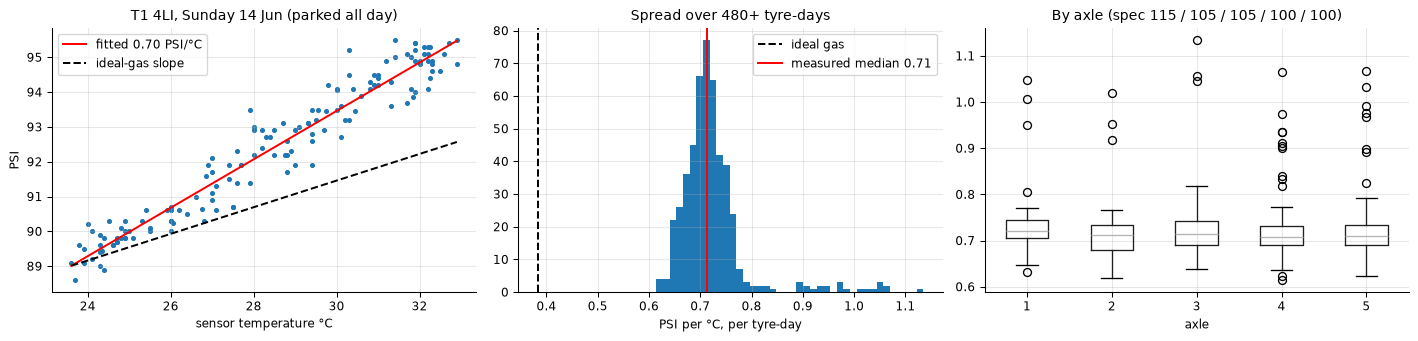

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
g = ZZ[(ZZ.veh=="KA25AB4471")&(ZZ.slot=="4LI")&(ZZ.day=="2026-06-14")]
ax[0].scatter(g.temp, g.psi, s=8); xs = np.array([g.temp.min(), g.temp.max()])
k, c = np.polyfit(g.temp, g.psi, 1); ax[0].plot(xs, k*xs+c, "r", label=f"fitted {k:.2f} PSI/°C")
ax[0].plot(xs, k*xs[0]+c + (xs-xs[0])*F.gaslaw_slope.median(), "k--", label="ideal-gas slope")
ax[0].set_xlabel("sensor temperature °C"); ax[0].set_ylabel("PSI"); ax[0].legend(); ax[0].set_title("T1 4LI, Sunday 14 Jun (parked all day)")
ax[1].hist(F.slope_psi_per_C, bins=40, color="C0"); ax[1].axvline(F.gaslaw_slope.median(), color="k", ls="--", label="ideal gas")
ax[1].axvline(BETA, color="r", label=f"measured median {BETA:.2f}"); ax[1].legend(); ax[1].set_xlabel("PSI per °C, per tyre-day"); ax[1].set_title("Spread over 480+ tyre-days")
F["axle"] = F.slot.astype(str).str[0]; F.boxplot(column="slope_psi_per_C", by="axle", ax=ax[2]); ax[2].set_title("By axle (spec 115 / 105 / 105 / 100 / 100)"); plt.suptitle("")
plt.tight_layout(); plt.show()

**Finding 2 — the sensor's pressure moves ≈ 0.71 PSI per reported °C: about 1.8× what the gas law predicts from the reported temperature, and the same on every tyre and every truck.** r ≈ 0.97 within a day; the slope does not scale with the tyre's pressure level (steer at 115 PSI is no steeper than a drive tyre at 100), which a gas-law effect would (by ~12%).

*Interpretation (hypothesis, not proven):* the reported temperature is the **valve-stem sensor body**, which swings less than the gas inside the tyre, so the sensor's °C understates the true gas temperature swing by roughly half. *Practical consequence (solid):* textbook temperature compensation with the TPMS temperature would **under-correct by almost half**; I use the empirical 0.71 PSI/°C instead, referenced to 25 °C (typical early-morning ambient, i.e. the "cold" the spec sheet means).

*What would change my mind:* the vendor documenting the temperature probe location, or a reference-gauge/IR-gun reading of gas or rim temperature on a parked truck.

**Check that the compensation works:** a compensated series should stay flat through the heat cycle while raw pressure swings by tens of PSI.

Within-day 5-95% range over all 3,780 tyre-days:
  raw PSI         : median  13.6  90th percentile  20.2 PSI
  compensated PSI : median   1.5  90th percentile   1.8 PSI   (includes real fills/leaks and residual error)


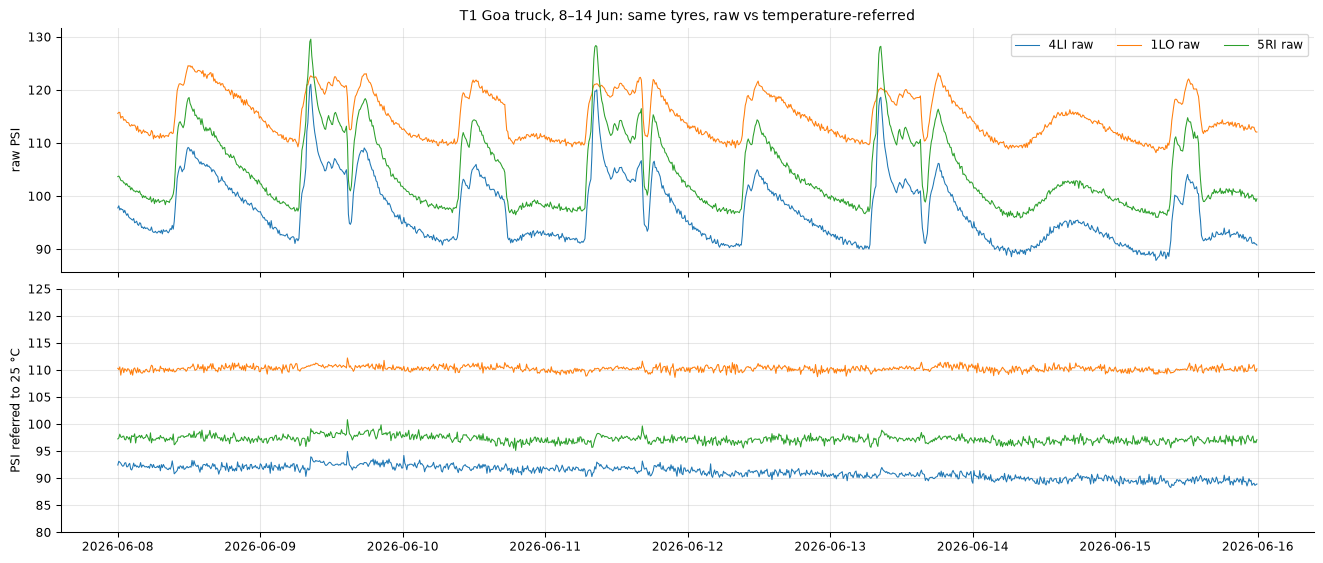

In [10]:
L["t10"] = L.t.dt.floor("10min")
B10 = L.groupby(["veh","slot","t10"], observed=True).agg(psi=("psi","median"), temp=("temp","median"), batt=("batt","median")).reset_index()
B10["pc"] = B10.psi - BETA*(B10.temp - T_REF)                        # PSI referred to 25 degC
B10["spec"] = B10.slot.astype(str).map(spec_of); B10["day"] = B10.t10.dt.floor("D")
for c in ["veh","slot"]: B10[c] = B10[c].astype(str)
grid = lambda col: B10.pivot_table(index="t10", columns=["veh","slot"], values=col).asfreq("10min")
PSI, TMP, PC = grid("psi"), grid("temp"), grid("pc")
SPECROW = pd.Series({(v, s): spec_of(s) for v, s in PC.columns})

# within-day swing, raw vs compensated, per tyre-day
rng = B10.groupby(["veh","slot","day"]).agg(raw=("psi", lambda s: s.quantile(.95)-s.quantile(.05)), comp=("pc", lambda s: s.quantile(.95)-s.quantile(.05)))
print("Within-day 5-95% range over all 3,780 tyre-days:")
print(f"  raw PSI         : median {rng.raw.median():5.1f}  90th percentile {rng.raw.quantile(.9):5.1f} PSI")
print(f"  compensated PSI : median {rng.comp.median():5.1f}  90th percentile {rng.comp.quantile(.9):5.1f} PSI   (includes real fills/leaks and residual error)")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
sel = [("KA25AB4471","4LI"), ("KA25AB4471","1LO"), ("KA25AB4471","5RI")]
for (v, s) in sel:
    ax[0].plot(PSI.loc["2026-06-08":"2026-06-15", (v, s)], lw=.8, label=f"{s} raw"); ax[1].plot(PC.loc["2026-06-08":"2026-06-15", (v, s)], lw=.8, label=f"{s} @25°C")
ax[0].set_ylabel("raw PSI"); ax[1].set_ylabel("PSI referred to 25 °C"); ax[0].legend(ncol=3); ax[0].set_title("T1 Goa truck, 8–14 Jun: same tyres, raw vs temperature-referred")
ax[1].set_ylim(80, 125); plt.tight_layout(); plt.show()

On a typical tyre-day the raw series swings ~14 PSI from temperature alone (more on the hottest days; see the 90th percentile above); the referred series swings ~1.5 PSI and shows mostly genuine events — a fill, a release, a leak. **This is the single most important transformation in the notebook**; everything about "which tyre" below depends on it.

## 3. "Fourteen alarms every afternoon" — what the Goa truck is actually doing

**Question.** Mr Vijayan: *"Every afternoon in June the Goa truck's alerts were going off, all fourteen tyres at once… next morning everything is normal again."*

**Physical reasoning.** Fourteen tyres do not puncture together. A common-mode drop in all tyres is a **common cause**: temperature (cooling) or a depot action. Cooling can be (a) the truck stopping after a hot descent, or (b) cold water — rain, spray, a wash — on hot tyres. I look at where the truck is (GPS), what the temperature does, and whether *other* trucks show the same thing at the same time.

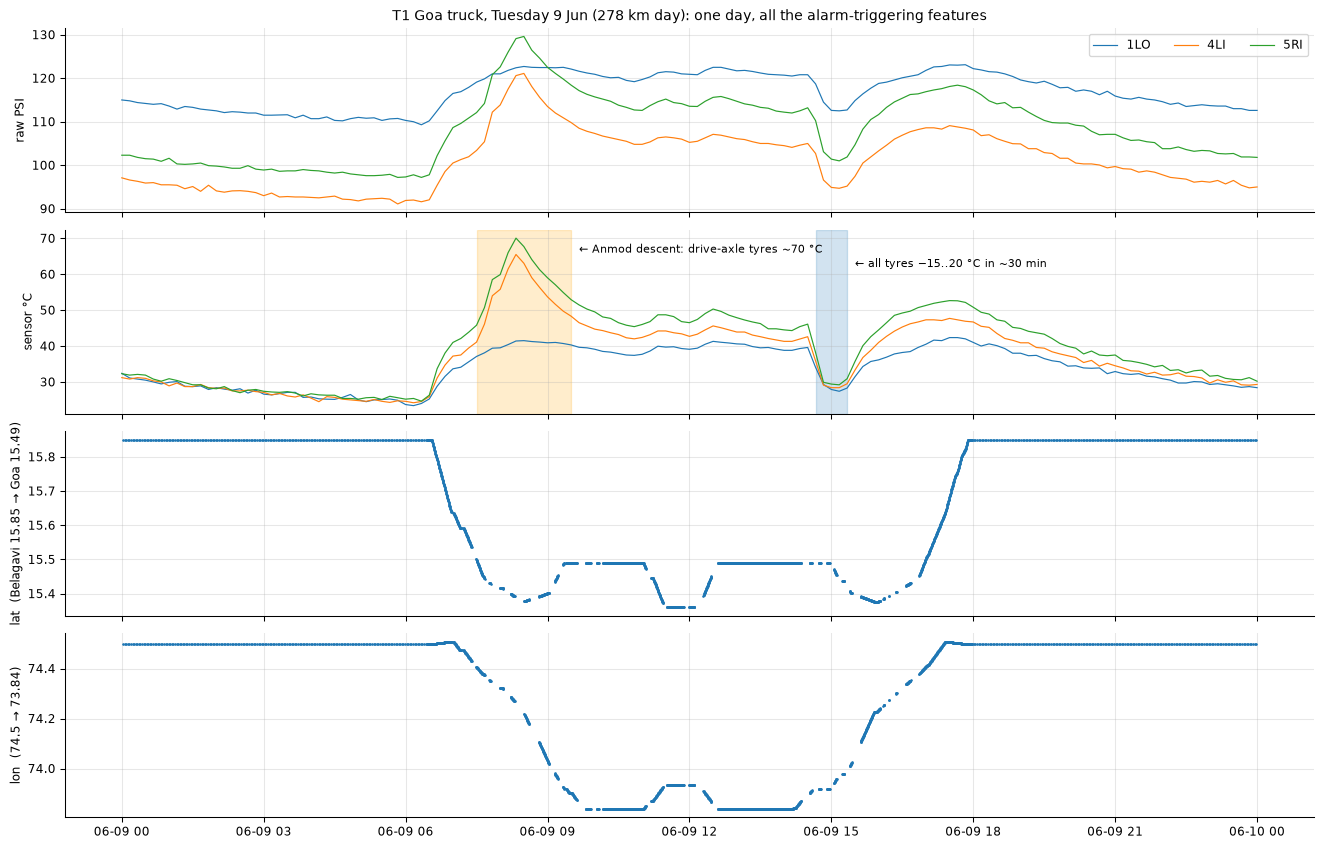

In [11]:
v = "KA25AB4471"; day0, day1 = pd.Timestamp("2026-06-09"), pd.Timestamp("2026-06-10")
m = df[(df.Vehicle==v)&(df.Time>=day0)&(df.Time<day1)]
fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for s, c in [("1LO","C0"),("4LI","C1"),("5RI","C2")]:
    ax[0].plot(PSI.loc[day0:day1, (v, s)], c, lw=.9, label=s); ax[1].plot(TMP.loc[day0:day1, (v, s)], c, lw=.9)
ax[0].set_ylabel("raw PSI"); ax[0].legend(ncol=3); ax[1].set_ylabel("sensor °C")
ax[2].plot(m.Time, m.Latitude, ".", ms=2); ax[2].set_ylabel("lat  (Belagavi 15.85 → Goa 15.49)")
ax[3].plot(m.Time, m.Longitude, ".", ms=2); ax[3].set_ylabel("lon  (74.5 → 73.84)")
for a, (t0, t1, lab) in zip([ax[1]], [("2026-06-09 07:30","2026-06-09 09:30","Anmod descent: drive-axle tyres ~70 °C")]):
    a.axvspan(pd.Timestamp(t0), pd.Timestamp(t1), color="orange", alpha=.2); a.text(pd.Timestamp("2026-06-09 09:40"), 66, "← Anmod descent: drive-axle tyres ~70 °C", fontsize=8)
ax[1].axvspan(pd.Timestamp("2026-06-09 14:40"), pd.Timestamp("2026-06-09 15:20"), color="C0", alpha=.2); ax[1].text(pd.Timestamp("2026-06-09 15:30"), 62, "← all tyres −15..20 °C in ~30 min", fontsize=8)
ax[0].set_title("T1 Goa truck, Tuesday 9 Jun (278 km day): one day, all the alarm-triggering features"); plt.tight_layout(); plt.show()

On a Goa day the truck leaves Belagavi ~06:30, descends the Anmod ghat (drive-axle tyres reach ~70 °C by 08:30 while steer/axle-2/3 tyres stay at 40–50 °C — brake heat reaching the drive wheels), is parked in Goa until ~14:45, then **all tyres lose 15–20 °C in about half an hour as it leaves**, and pressure falls 10–20 PSI with it. That is a thermal event, not an air loss: the pressure recovers as the tyres warm up again on the climb.

**Is it rain?** The Goa data alone can't say. Test: if the cause is weather, **other trucks should show simultaneous cooling on the same dates**, whatever route they are on.

In [12]:
VT = B10.groupby(["veh","t10"]).temp.median().unstack(0).asfreq("10min")        # vehicle-level median tyre temperature
dT30 = VT - VT.shift(3)                                                         # change over 30 min
rows = []
for v in VT.columns:
    for d, g in dT30[v].groupby(dT30.index.floor("D")):
        if g.notna().sum() < 50: continue
        rows.append((v, d, g.idxmin(), g.min()))
EV = pd.DataFrame(rows, columns=["veh","day","t","dT30"])
EV = EV[EV.dT30 <= -8]
def sync_count(g):
    best = 0
    for t0 in g.t:
        best = max(best, ((g.t - t0).abs() <= pd.Timedelta("20min")).sum())
    return best
daily = EV.groupby("day").apply(lambda g: pd.Series({"trucks_with_cooling_event": g.veh.nunique(), "max_trucks_within_20min": sync_count(g),
                 "times": ", ".join(f"{NAME[r.veh].split()[0]}@{r.t:%H:%M}" for r in g.sort_values("t").itertuples())}))
sync = daily[daily.max_trucks_within_20min >= 4]
print(f"Dates on which >=4 of 6 trucks show a >=8°C/30-min cooling event within 20 min of each other: {len(sync)}")
sync

Dates on which >=4 of 6 trucks show a >=8°C/30-min cooling event within 20 min of each other: 10


,trucks_with_cooling_event,max_trucks_within_20min,times
day,,,
2026-06-10,5,4,"T2@16:30, T6@17:30, T5@17:30, T3@17:40, T4@17:40"
2026-06-11,6,5,"T3@14:20, T6@14:20, T2@14:20, T4@14:20, T5@14:..."
2026-06-13,6,6,"T3@15:40, T6@15:40, T1@15:40, T2@15:40, T4@15:..."
2026-06-17,6,5,"T2@11:30, T6@12:40, T1@12:40, T4@12:40, T5@12:..."
2026-06-27,6,5,"T3@14:40, T6@14:40, T2@14:40, T4@14:40, T5@14:..."
2026-07-04,6,5,"T1@16:50, T3@17:40, T6@17:40, T2@17:40, T5@17:..."
2026-07-07,5,5,"T3@16:00, T6@16:00, T4@16:00, T5@16:00, T1@16:10"
2026-07-09,5,4,"T6@12:30, T2@12:40, T4@12:40, T3@12:50, T1@16:30"
2026-07-10,6,5,"T1@13:10, T4@13:10, T3@13:20, T5@13:20, T6@13:..."


In [13]:
# How often does the Goa truck really have an "all-tyre" afternoon cooling? (>=10 of 14 tyres down >=8 degC in 30 min, 12:00-18:00)
Tg = TMP.loc[:, [c for c in TMP.columns if c[0]=="KA25AB4471"]].droplevel(0, axis=1)
n_cool = ((Tg.shift(3) - Tg) >= 8).sum(axis=1)
aft = n_cool[(n_cool.index.hour>=12)&(n_cool.index.hour<18)]
days_aft = aft[aft>=10].groupby(aft[aft>=10].index.floor("D")).size().index
print(f"T1 Goa: days with an all-tyre afternoon cooling event: {len(days_aft)} of 45  (June: {sum(d.month==6 for d in days_aft)} of 30)")
print([d.strftime('%d-%b') for d in days_aft])

T1 Goa: days with an all-tyre afternoon cooling event: 17 of 45  (June: 10 of 30)
['09-Jun', '11-Jun', '13-Jun', '15-Jun', '16-Jun', '17-Jun', '18-Jun', '23-Jun', '27-Jun', '30-Jun', '01-Jul', '02-Jul', '04-Jul', '07-Jul', '09-Jul', '10-Jul', '11-Jul']


**Finding 3 — the afternoon "all-tyre" drops are thermal events with a common external cause, consistent with rain, and they are neither "every afternoon" nor leaks.**

* On the dates above, four to six trucks on different roads (Hubballi city, Gadag, Vijayapura, Karwar, Shivamogga) show the same sudden all-tyre cooling in the same ~20-minute window. A puncture cannot do that to six trucks at once.
* The first synchronous events start on 10–11 Jun, matching the manager's "rain came early, second week of June".
* **Not literally every afternoon:** counting days with ≥10 of T1's 14 tyres cooling ≥8 °C in 30 min between 12:00 and 18:00 gives 17 of 45 days (10 of 30 in June). Memory exaggerates; the pattern is real.
* **Residual puzzle I cannot resolve:** the timing agrees to the *same 10-minute bin* across trucks 100+ km apart. Real showers are patchier than that. It is consistent with a widespread front, but I cannot exclude that the vendor's pipeline or the export introduces a shared component. *What would settle it:* rainfall records for Belagavi/Hubballi/Goa on 11 Jun, 13 Jun, 17 Jun, 27 Jun, 4 Jul, 7 Jul, 9 Jul, 14 Jul, or asking the drivers.
* Separate from weather, T1 and T2 cool-down every day after their descents (T1 ~09:00, T2 ~11:40) — routine, not faults.

*Confidence:* high that these are thermal/common-cause and not tyre faults; moderate that rain is the cause (no weather data in the pack).

In [14]:
# Which KIND of alert reproduces "all fourteen at once, pressure dropping, normal next morning"?
# The vendor's alert rules are NOT in the pack, so I test the two generic families against the data.
def load_table(F, name):
    rows = []
    for v_ in VEH_ORDER:
        cols = [c for c in F.columns if c[0]==v_]; f = F[cols]; n = f.sum(axis=1)
        tyre_days = int(f.groupby(f.index.floor("D")).any().sum().sum())                       # tyre-days with >=1 alarm (max 14 x 45 = 630)
        mass = n >= 10; mass_days = int(mass.groupby(mass.index.floor("D")).any().sum())        # days with >=10 tyres alarming at once
        aft = mass[(mass.index.hour>=12)&(mass.index.hour<18)]; aft_days = int(aft.groupby(aft.index.floor("D")).any().sum())
        rows.append((name, NAME[v_], tyre_days, mass_days, aft_days))
    return pd.DataFrame(rows, columns=["rule","truck","tyre_days_alarmed_of_630","days_with_10+_tyres_at_once","...of_which_in_afternoon"])
RULES = {
    "A. fixed LOW, raw PSI < 90% of card":         PSI < 0.90*SPECROW,
    "B. RAPID FALL, raw PSI down >= 8 in 30 min":  (PSI.shift(3) - PSI) >= 8,
    "C. fixed LOW, temperature-referred PSI":      PC  < 0.90*SPECROW,
}
LT = pd.concat([load_table(F, n) for n, F in RULES.items()])
for rule, g in LT.groupby("rule"):
    print("\n" + rule); display(g.drop(columns="rule").set_index("truck"))


A. fixed LOW, raw PSI < 90% of card


,tyre_days_alarmed_of_630,days_with_10+_tyres_at_once,...of_which_in_afternoon
truck,,,
T1 Goa,5,0,0
T2 Karwar,1,0,0
T6 Vijayapura,0,0,0
T3 Gadag,497,35,7
T4 City,341,17,3
T5 Shivamogga,410,28,3



B. RAPID FALL, raw PSI down >= 8 in 30 min


,tyre_days_alarmed_of_630,days_with_10+_tyres_at_once,...of_which_in_afternoon
truck,,,
T1 Goa,193,12,12
T2 Karwar,189,6,6
T6 Vijayapura,120,7,7
T3 Gadag,107,3,3
T4 City,37,0,0
T5 Shivamogga,65,2,2



C. fixed LOW, temperature-referred PSI


,tyre_days_alarmed_of_630,days_with_10+_tyres_at_once,...of_which_in_afternoon
truck,,,
T1 Goa,7,0,0
T2 Karwar,1,0,0
T6 Vijayapura,0,0,0
T3 Gadag,542,41,40
T4 City,391,15,15
T5 Shivamogga,479,31,15


**Finding 3b — a *rapid-fall* alert, not a *low-pressure* alert, is what the manager is describing.** (The vendor's rules are not in the pack; this is inference from the shape of his complaint and from what each rule family would do.)

* **Rule A (fixed low threshold on raw PSI)** is almost silent on T1/T2/T6 (5, 1 and 0 tyre-days of 630: Belagavi, cold-filled) and loud only on the Hubballi trucks (35, 17 and 28 days with ≥10 tyres under at once), where it is *right* to be: those tyres really are 7–10% under the card when cold (Section 4). Note that in the afternoons raw readings are inflated by heat, so A *hides* the Hubballi under-inflation exactly when the depot is filling them (compare the afternoon columns of A and C for T3: 7 vs 40 days).
* **Rule B (raw pressure falling ≥8 PSI in 30 min)** produces the manager's picture: on the **Goa truck, 12 afternoons with ≥10 tyres alarming together**, more than any other truck (T2 6, T6 7, T3 3, T5 2, T4 0), on days when nothing is wrong with any tyre. Many tyres at once, pressure dropping, nothing wrong next morning.
* **Rule C (low threshold on temperature-referred PSI)** removes the thermal noise but fires on Hubballi's chronic under-inflation every day (T3: 41 of 45 days), which is a *procedure* defect, not a tyre fault.

Implication for the client's real ask ("one alarm, one tyre"): the fix is neither a better threshold nor a bigger alarm count. It is **comparing each tyre with its own history and its neighbours after removing temperature** (Section 7), plus fixing the Hubballi procedure so that the chronic alarm disappears.

## 4. How the depots actually inflate — and why the Hubballi trucks "always read low"

**The manager's beliefs to test:** (1) *"Hubballi trucks leak more because of bad roads"*; (2) the gauge "is probably fine" but has never been compared with TyreSense; (3) each truck is checked "once in ten-fifteen days"; (4) Belagavi fills first thing in the morning, Hubballi in the afternoon.

**Physical reasoning.** The standard is a **cold** pressure (spec sheet: "before the vehicle has run, or after it has stood for at least three hours; a running tyre will read higher"). Fill a tyre to the card number while it is hot and, once it cools, it sits *below* the card by roughly β·ΔT ≈ 0.71 × (hot − 25 °C) — 8–17 PSI for tyres at 35–50 °C. Releasing air from a hot tyre that reads "above the card" is the same error in the other direction. A depot that fills cold (06:00) gets it right; one that fills hot (afternoon) gets it wrong *by procedure alone*, with no leak involved.

**Method.** Detect depot interventions directly in the data: a pressure step (referred to 25 °C, so temperature can't fake it) of ≥3.5 PSI within 20 minutes with <2 °C temperature change. Cluster into sessions per truck; measure the reading before and after against the card.

In [15]:
dpc = PC.shift(-1) - PC.shift(1); dtemp = (TMP.shift(-1) - TMP.shift(1)).abs()
mask = (dpc.abs() >= 3.5) & (dtemp < 2.0)
ev = mask.stack([0, 1]); ev = ev[ev].reset_index().iloc[:, :3]; ev.columns = ["t","veh","slot"]
ev["dpc"] = [dpc.loc[t, (v, s)] for t, v, s in zip(ev.t, ev.veh, ev.slot)]
ev["dir"] = np.where(ev.dpc > 0, "fill", "release")
ev = ev.sort_values(["veh","dir","t"]).reset_index(drop=True)
ev["session"] = ((ev.veh != ev.veh.shift()) | (ev.dir != ev.dir.shift()) | (ev.t.diff() > pd.Timedelta("60min"))).cumsum()

def level(series, a, b):
    x = series.loc[a:b].dropna(); return x.median() if len(x) >= 2 else np.nan
rows = []
for sid, g in ev.groupby("session"):
    v, d = g.veh.iloc[0], g.dir.iloc[0]
    for r in g.itertuples():
        te, sp = r.t, spec_of(r.slot)
        pre  = level(PSI[(v, r.slot)], te - pd.Timedelta("50min"), te - pd.Timedelta("15min"))
        post = level(PSI[(v, r.slot)], te + pd.Timedelta("15min"), te + pd.Timedelta("40min"))
        tpost = level(TMP[(v, r.slot)], te + pd.Timedelta("15min"), te + pd.Timedelta("40min"))
        rows.append((sid, v, d, te, r.slot, sp, pre - sp, post - sp, tpost, post - BETA*(tpost - T_REF) - sp))
LV = pd.DataFrame(rows, columns=["session","veh","dir","t","slot","spec","pre_gap_raw","post_gap_raw","temp_after","post_gap_at25C"])
SESS = (LV.groupby("session").agg(truck=("veh", lambda s: NAME[s.iloc[0]]), depot=("veh", lambda s: DEPOT[s.iloc[0]]), dir=("dir","first"),
        start=("t","min"), tyres=("slot","nunique"), temp_after_C=("temp_after","median"),
        before_vs_card_raw=("pre_gap_raw","median"), after_vs_card_raw=("post_gap_raw","median"), after_vs_card_when_cold=("post_gap_at25C","median"))
        .round(1))
BIG = SESS[SESS.tyres >= 3].sort_values(["depot","start"]); SMALL = SESS[SESS.tyres < 3]
print("Truck-wide depot sessions (>=3 tyres):"); display(BIG)

Truck-wide depot sessions (>=3 tyres):


,truck,depot,dir,start,tyres,temp_after_C,before_vs_card_raw,after_vs_card_raw,after_vs_card_when_cold
session,,,,,,,,,
8,T2 Karwar,Belagavi,fill,2026-06-07 06:00:00,7,27.0,-4.9,0.0,-1.5
4,T6 Vijayapura,Belagavi,fill,2026-06-10 06:20:00,14,24.3,-6.2,-0.2,0.4
6,T1 Goa,Belagavi,fill,2026-06-18 05:50:00,11,26.0,-5.4,1.1,-0.1
9,T2 Karwar,Belagavi,fill,2026-06-21 06:20:00,9,23.9,-3.5,0.7,1.2
15,T4 City,Hubballi,release,2026-06-04 15:30:00,8,43.9,5.5,-0.6,-13.9
3,T3 Gadag,Hubballi,release,2026-06-05 15:30:00,13,47.9,7.4,-0.1,-17.0
13,T4 City,Hubballi,fill,2026-06-18 15:40:00,13,37.1,-5.1,-0.0,-8.4
1,T3 Gadag,Hubballi,fill,2026-06-19 15:40:00,14,40.2,-6.1,-0.1,-10.4
14,T4 City,Hubballi,fill,2026-07-02 15:30:00,4,35.0,-3.0,1.0,-6.0


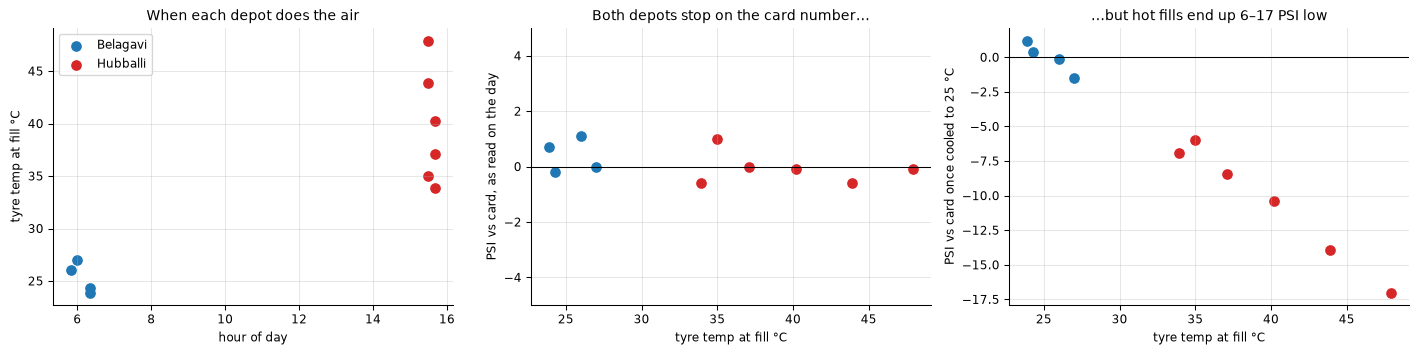

Reading just after any depot session vs the card number, all 188 tyre-sessions: mean +0.12 PSI, median +0.00, sd 1.21


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for dep, c in [("Belagavi","C0"),("Hubballi","C3")]:
    b = BIG[BIG.depot==dep]
    ax[0].scatter(b.start.dt.hour + b.start.dt.minute/60, b.temp_after_C, c=c, s=50, label=dep)
    ax[1].scatter(b.temp_after_C, b.after_vs_card_raw, c=c, s=50)
    ax[2].scatter(b.temp_after_C, b.after_vs_card_when_cold, c=c, s=50)
ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("tyre temp at fill °C"); ax[0].legend(); ax[0].set_title("When each depot does the air")
ax[1].axhline(0, c="k", lw=.8); ax[1].set_ylim(-5, 5); ax[1].set_xlabel("tyre temp at fill °C"); ax[1].set_ylabel("PSI vs card, as read on the day"); ax[1].set_title("Both depots stop on the card number…")
ax[2].axhline(0, c="k", lw=.8); ax[2].set_xlabel("tyre temp at fill °C"); ax[2].set_ylabel("PSI vs card once cooled to 25 °C"); ax[2].set_title("…but hot fills end up 6–17 PSI low")
plt.tight_layout(); plt.show()

allpost = LV[LV.session.isin(BIG.index)]
print(f"Reading just after any depot session vs the card number, all {len(allpost)} tyre-sessions: mean {allpost.post_gap_raw.mean():+.2f} PSI, median {allpost.post_gap_raw.median():+.2f}, sd {allpost.post_gap_raw.std():.2f}")

**Finding 4a — the Hubballi "always low" is the depot's procedure, not leakage.**

| | Belagavi (T1, T2, T6) | Hubballi (T3, T4, T5) |
|---|---|---|
| When | ~06:00–06:30, tyres at ~23–27 °C | ~15:30–16:00, tyres at ~34–48 °C |
| Reading when they stop | ≈ the card (mean error ≈ 0) | ≈ the card (mean error ≈ 0) |
| After cooling to 25 °C | ≈ the card (−1.5…+1.5 PSI) | **6–10 PSI under** (fills), **12–17 PSI under** (releases) |

* Every session lands on the card number *as read at the time*; only the temperature at that moment differs. The manager's "ninety, ninety-one on the drive tyres next morning" is what a hot fill to 100 produces (100 − ~9).
* **There are also hot *releases* at Hubballi** (T4 on 4 Jun, T3 on 5 Jun at ~15:50): tyres reading a median 5–7 PSI above the card because they were hot were bled *down* to the card, taking T3 to about **17 PSI (≈16%) below standard when cold**, for two weeks, until the hot fill on 19 Jun partly recovered it (T5 shows a smaller one on 8 Jun). The manager did not mention this and may not know.
* **Gauge vs TyreSense (the question he said he never checked):** across all 188 tyre-sessions in truck-wide interventions the TPMS reading just after the filler stops differs from the card by a mean of +0.1 PSI (median 0.0, sd 1.2). So the dial gauge and the sensors **agree** to about a PSI at the filling moment. Caveat: this only shows they agree with each other *there*; if both were off by the same amount I couldn't tell.
* **Frequency:** truck-wide sessions occur about every 2–5 weeks per truck (2–3 in 45 days), not "ten–fifteen days"; plus occasional one- or two-tyre top-ups (next table). The two T2 "release" rows on 11 Jul are the failing tyre itself (Section 5), a useful sanity check that the detector sees real events.

*Confidence:* high on the hot-fill mechanism (it explains the sign, size, timing and his own quoted numbers). *Would change my mind:* a depot log showing fills were actually done cold, or evidence the TPMS reads systematically low only in the afternoon.

In [17]:
print("Single/two-tyre interventions (n<3 tyres), >=3.5 PSI step:")
display(SMALL.sort_values("start"))

Single/two-tyre interventions (n<3 tyres), >=3.5 PSI step:


,truck,depot,dir,start,tyres,temp_after_C,before_vs_card_raw,after_vs_card_raw,after_vs_card_when_cold
session,,,,,,,,,
18,T5 Shivamogga,Hubballi,release,2026-06-08 15:30:00,2,41.2,3.9,-0.8,-12.2
16,T5 Shivamogga,Hubballi,fill,2026-06-22 15:30:00,1,37.1,-2.5,0.2,-8.4
2,T3 Gadag,Hubballi,fill,2026-07-03 15:40:00,2,37.4,-5.0,-0.1,-8.9
7,T1 Goa,Belagavi,fill,2026-07-04 05:50:00,1,23.8,-7.3,0.1,1.0
10,T2 Karwar,Belagavi,fill,2026-07-05 06:10:00,2,22.8,-5.5,0.1,1.5
11,T2 Karwar,Belagavi,release,2026-07-11 07:00:00,1,44.4,-14.0,-22.0,-35.8
12,T2 Karwar,Belagavi,release,2026-07-11 10:20:00,1,48.0,-44.6,-55.6,-72.8
5,T6 Vijayapura,Belagavi,fill,2026-07-13 06:30:00,1,24.5,-3.6,0.5,0.9


In [18]:
# beta-independent check of the "cold state": readings at 00:00-05:00 when sensor temp is 22-30 degC (correction < 4 PSI either way)
N = B10[(B10.t10.dt.hour < 5) & B10.temp.between(22, 30)].copy(); N["gap_raw"] = N.psi - N.spec
last14 = N[N.day >= "2026-07-02"]
cold = last14.groupby("veh").agg(median_gap_PSI=("gap_raw","median"), p10=("gap_raw", lambda s: s.quantile(.1)), p90=("gap_raw", lambda s: s.quantile(.9)), temp=("temp","median")).round(1)
cold["pct_of_card"] = (100*cold.median_gap_PSI/ last14.groupby("veh").spec.median()).round(1)
cold.index = [NAME[v] for v in cold.index]; cold.loc[[NAME[v] for v in VEH_ORDER]]

,median_gap_PSI,p10,p90,temp,pct_of_card
T1 Goa,0.0,-1.6,1.6,26.0,0.0
T2 Karwar,0.4,-1.5,2.5,26.0,0.4
T6 Vijayapura,-0.1,-1.7,1.5,25.7,-0.1
T3 Gadag,-9.9,-12.2,-7.2,26.8,-9.9
T4 City,-7.4,-9.7,-4.6,26.3,-7.4
T5 Shivamogga,-10.0,-11.8,-7.1,25.6,-10.0


In the final fortnight, the three Belagavi trucks sit within ±0.5 PSI of the card when cold; the three Hubballi trucks sit **7–10 PSI under (7–10%)**. This table uses **raw** readings in the 22–30 °C window, so it does not depend on my temperature coefficient at all.

**Is under-inflation of 8–15% harmful?** The spec sheet itself says visual inspection cannot detect 10–15% under-inflation, and that running substantially under standard overheats the casing, shortens life, and overloads the twin. Cost is real but slow; nothing in the tread sheets shows it yet (Section 8) — six weeks is too short for wear shape to appear.

PSI change per 30 days (negative = loss). Spec allows up to ~3 PSI/month.
          count  mean   std    min   25%   50%   75%   max
depot                                                     
Belagavi   42.0 -1.85  2.00 -11.59 -1.75 -1.36 -1.10  0.45
Hubballi   42.0 -1.99  1.96 -12.46 -1.83 -1.55 -1.23 -0.37

Median: Hubballi -1.55 vs Belagavi -1.36 PSI/30d;  Mann-Whitney p = 0.24
By truck (median PSI/30d): {'T3 Gadag': -1.51, 'T6 Vijayapura': -1.33, 'T1 Goa': -1.34, 'T2 Karwar': -1.74, 'T4 City': -1.61, 'T5 Shivamogga': -1.42}


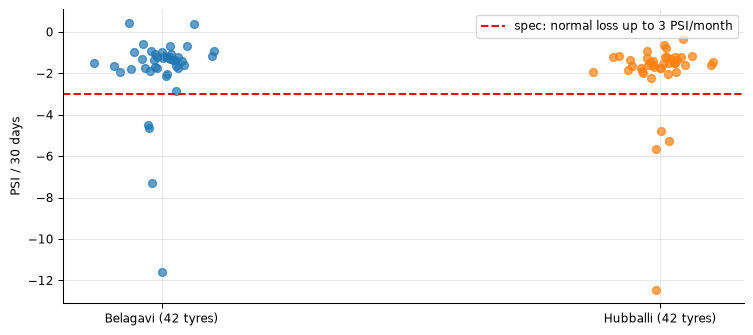

In [19]:
# Leak rates between interventions, by depot. Nightly (00:00-02:30) temperature-referred pressure per tyre; day-to-day changes
# excluding steps >2 PSI (fills/releases/top-ups).
NIGHT = B10[B10.t10.dt.hour < 3].groupby(["veh","slot","day"]).pc.median().unstack("day")
rows = []
for (v, s), x in NIGHT.iterrows():
    d = x.dropna().diff().dropna(); d = d[d.abs() < 2.0]
    rows.append((v, s, d.mean()*30, len(d)))
LEAK = pd.DataFrame(rows, columns=["veh","slot","psi_per_30d","n_days"]); LEAK["depot"] = LEAK.veh.map(DEPOT)
print("PSI change per 30 days (negative = loss). Spec allows up to ~3 PSI/month.")
print(LEAK.groupby("depot").psi_per_30d.describe().round(2))
a, b_ = LEAK[LEAK.depot=="Hubballi"].psi_per_30d, LEAK[LEAK.depot=="Belagavi"].psi_per_30d
print(f"\nMedian: Hubballi {a.median():.2f} vs Belagavi {b_.median():.2f} PSI/30d;  Mann-Whitney p = {stats.mannwhitneyu(a, b_).pvalue:.2f}")
print("By truck (median PSI/30d):", LEAK.groupby("veh").psi_per_30d.median().rename(index=NAME).round(2).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, dep in enumerate(["Belagavi","Hubballi"]):
    y = LEAK[LEAK.depot==dep].psi_per_30d; ax.scatter(np.random.default_rng(1).normal(i, .05, len(y)), y, alpha=.7)
ax.axhline(-3, c="r", ls="--", label="spec: normal loss up to 3 PSI/month"); ax.set_xticks([0,1]); ax.set_xticklabels(["Belagavi (42 tyres)","Hubballi (42 tyres)"]); ax.set_ylabel("PSI / 30 days"); ax.legend(); plt.tight_layout(); plt.show()

**Finding 4b — there is no evidence that Hubballi trucks leak more.** The typical tyre loses ~1.3–1.7 PSI/month on *every* truck, inside the manufacturer's allowance, with no detectable difference between depots (medians −1.4 vs −1.6 PSI/month, p = 0.24). The manager's belief is the hot-fill artefact misread as leakage. A handful of individual tyres **do** leak far faster than normal (the tail of the plot) — they are listed in Section 6 and are the real "which tyre" candidates.

*What this does not test:* whether Hubballi roads wear tyres faster. Pressure leakage is the wrong instrument for that; wear needs tread depth over time, which the pack has for one truck only (Section 8).

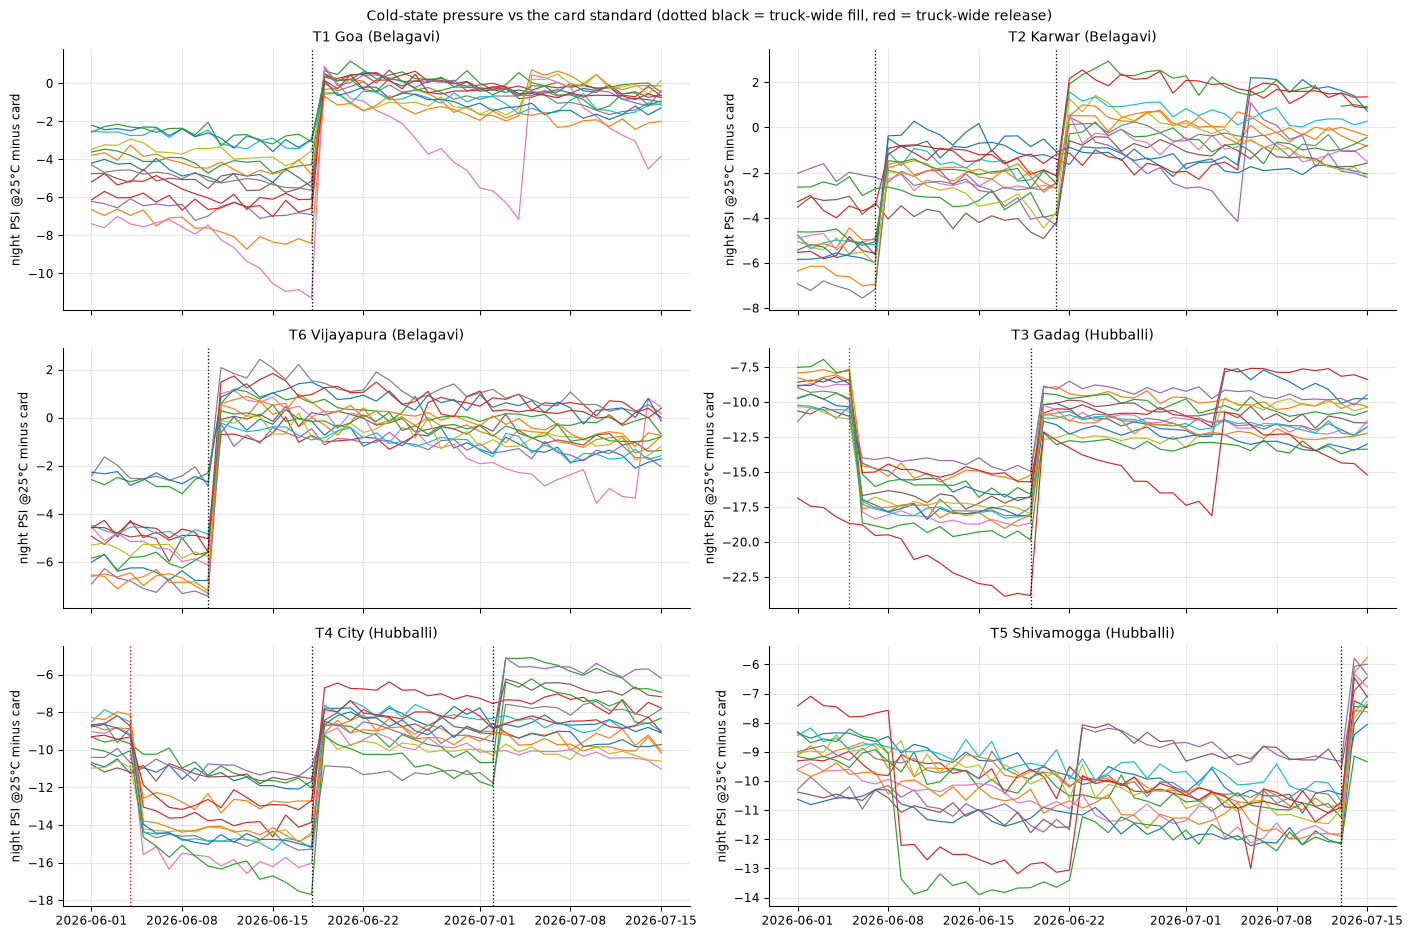

In [20]:
# The cold-state history of every tyre vs its card, one panel per truck: fills (up-steps), releases (down-steps), slow leaks (slopes)
fig, axs = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for a, v in zip(axs.ravel(), VEH_ORDER):
    x = NIGHT.loc[v]
    for s in x.index:
        a.plot(x.columns, x.loc[s] - spec_of(s), lw=.9)
    a.set_title(f"{NAME[v]} ({DEPOT[v]})"); a.set_ylabel("night PSI @25°C minus card")
    for r in BIG[BIG.truck==NAME[v]].itertuples(): a.axvline(r.start.normalize(), c="k" if r.dir=="fill" else "r", ls=":", lw=1)
fig.suptitle("Cold-state pressure vs the card standard (dotted black = truck-wide fill, red = truck-wide release)"); plt.tight_layout(); plt.show()

Reading the panels: **steps up** are fills; **steps down** (T3 5 Jun, T4 4 Jun) are hot releases; slow downward drifts are leaks. Belagavi trucks (top three) oscillate around zero. Hubballi trucks (bottom three) live 8–18 PSI under the card, T3 worst. Several individual tyres drift away from their truck-mates (T1 one tyre, T2 one, T3 one) — Section 6.

## 5. The Karwar failure: could it have been foreseen?

**Question (the director's).** An inner tyre on a twin failed on the road in July "with, as far as anyone knew, no warning". The register says T2 (Karwar truck) position **5RI**, removed roadside 11 Jul. Did the TPMS show anything, and how early?

**Physical reasoning.** A tyre that is failing mechanically either (a) **leaks** — pressure falls relative to its twin, which sits at the same pressure and sees the same heating — or (b) heats abnormally. A twin is the ideal control: same axle, same load path, same temperature, same fill. So the right signal is the **temperature-referred pressure of 5RI minus its twin 5RO**, not raw PSI against a threshold. I look at it (i) in the hours of failure, (ii) in the six weeks before for any slower precursor, and (iii) at what simple rules would have done.

In [21]:
v = "KA25AC1182"
w = L[(L.veh==v)&(L.t>="2026-07-10 12:00")&(L.t<"2026-07-12 00:00")].copy()
w["pc"] = w.psi - BETA*(w.temp - T_REF); w["t5"] = w.t.dt.floor("5min")
W5 = w.groupby(["t5","slot"], observed=True).agg(pc=("pc","median"), psi=("psi","median"), temp=("temp","median")).unstack("slot")
pair = (W5["pc"]["5RI"] - W5["pc"]["5RO"])

# onset: first 5-min bin where 5RI is >=2.5 PSI below its twin for 3 consecutive bins
low = (pair <= -2.5).astype(int); onset = low.index[(low.rolling(3).sum() == 3)][0] - pd.Timedelta("10min")
last_5ri = L[(L.veh==v)&(L.slot=="5RI")&L.psi.notna()&(L.t < "2026-07-12")].t.max()

# truck motion from GPS
g = df[(df.Vehicle==v)&(df.Time>="2026-07-11 01:00")&(df.Time<"2026-07-11 20:00")].dropna(subset=["Latitude"]).copy()
g["moved_m"] = hav(g.Latitude.shift(), g.Longitude.shift(), g.Latitude, g.Longitude)*1000
depart = g[(g.Time>="2026-07-11 02:00") & (g.moved_m > 100)].Time.min()
still = (g.moved_m < 30) & (g.Time >= "2026-07-11 06:00"); run_id = (still != still.shift()).cumsum()
runs = g[still].groupby(run_id[still]).agg(start=("Time","min"), end=("Time","max"), lat=("Latitude","median"), lon=("Longitude","median"))
stop = runs.assign(dur=runs.end-runs.start).sort_values("dur").iloc[-1]

def first_below(series_raw, thr, after):
    s = series_raw.loc[after:]; hit = s[s < thr]; return hit.index[0] if len(hit) else None
raw5 = W5["psi"]["5RI"]
t90, t85 = first_below(raw5, 90, onset), first_below(raw5, 85, onset)
print(f"Truck leaves Karwar yard (GPS):                 {depart:%d %b %H:%M}")
print(f"5RI starts diverging from its twin 5RO:        {onset:%d %b %H:%M}   (pair gap {pair.loc[onset+pd.Timedelta('30min')]:.1f} PSI after 30 min)")
print(f"Pair gap reaches -5 PSI:                       {pair[pair<=-5].index[0]:%H:%M}")
print(f"Raw 5RI falls below 90 PSI (90% of card):      {t90:%H:%M}    below 85 PSI: {t85:%H:%M}")
print(f"Truck stops for {stop.dur}  from {stop.start:%H:%M} to {stop.end:%H:%M} at {stop.lat:.3f}N {stop.lon:.3f}E  (road shoulder; 'near Kittur')")
print(f"Last 5RI reading before the sensor goes silent: {last_5ri:%H:%M}  at {W5['psi']['5RI'].dropna().iloc[-1]:.0f} PSI raw")
print(f"-> from first deviation to the stop: {(stop.start-onset)}, to sensor death: {(last_5ri-onset)}")

Truck leaves Karwar yard (GPS):                 11 Jul 03:07
5RI starts diverging from its twin 5RO:        11 Jul 03:20   (pair gap -10.2 PSI after 30 min)
Pair gap reaches -5 PSI:                       03:25
Raw 5RI falls below 90 PSI (90% of card):      06:25    below 85 PSI: 07:15
Truck stops for 0 days 03:51:46  from 12:16 to 16:07 at 15.660N 74.803E  (road shoulder; 'near Kittur')
Last 5RI reading before the sensor goes silent: 14:19  at 15 PSI raw
-> from first deviation to the stop: 0 days 08:56:05, to sensor death: 0 days 10:59:41


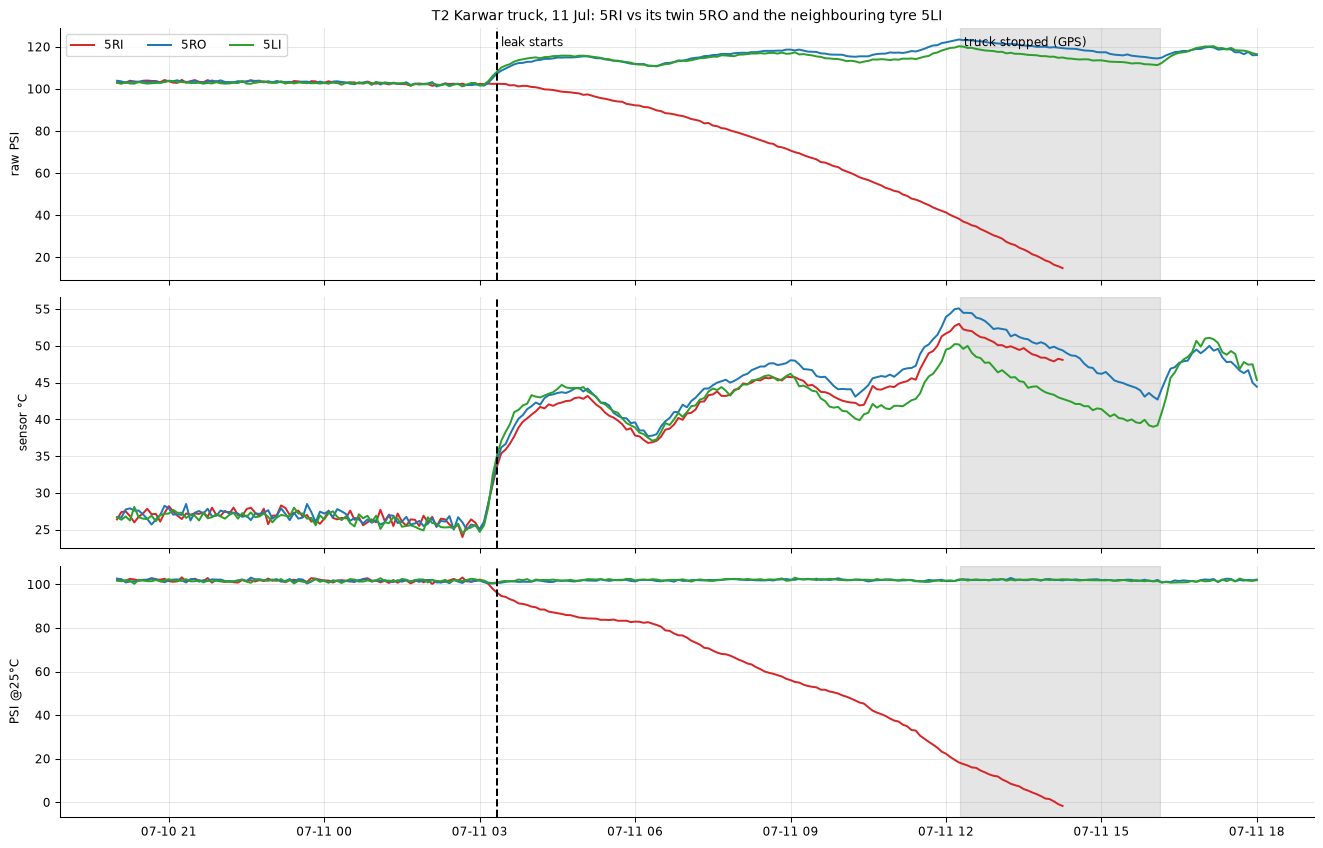

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
rng_ = slice("2026-07-10 20:00", "2026-07-11 18:00")
for s, c in [("5RI","C3"),("5RO","C0"),("5LI","C2")]:
    ax[0].plot(W5["psi"][s].loc[rng_], c, label=s); ax[1].plot(W5["temp"][s].loc[rng_], c); ax[2].plot(W5["pc"][s].loc[rng_], c)
ax[0].set_ylabel("raw PSI"); ax[1].set_ylabel("sensor °C"); ax[2].set_ylabel("PSI @25°C"); ax[0].legend(ncol=3)
for a in ax:
    a.axvline(onset, c="k", ls="--"); a.axvspan(stop.start, stop.end, color="grey", alpha=.2)
ax[0].text(onset, ax[0].get_ylim()[1]*.97, " leak starts", va="top"); ax[0].text(stop.start, ax[0].get_ylim()[1]*.97, " truck stopped (GPS)", va="top")
ax[0].set_title("T2 Karwar truck, 11 Jul: 5RI vs its twin 5RO and the neighbouring tyre 5LI"); plt.tight_layout(); plt.show()

In [23]:
# Six weeks BEFORE: any slower precursor? 5RI minus twin 5RO (temperature-referred), nightly, up to 10 Jul
Tn = B10[(B10.veh==v)&(B10.t10.dt.hour<3)&(B10.day<="2026-07-10")].pivot_table(index="day", columns="slot", values="pc")
dpair = (Tn["5RI"] - Tn["5RO"]); d_after_fill = dpair.loc["2026-06-22":]
lr = stats.linregress(np.arange(len(d_after_fill)), d_after_fill.values)
print("5RI minus twin 5RO, nightly, 22 Jun-10 Jul (after the last truck-wide fill): "
      f"mean {d_after_fill.mean():+.2f}, sd {d_after_fill.std():.2f}, min {d_after_fill.min():+.2f}, max {d_after_fill.max():+.2f} PSI;  trend {lr.slope:+.3f} PSI/day (p={lr.pvalue:.2f})")
others = [c for c in Tn.columns if c != "5RI"]; resid = (Tn["5RI"] - Tn[others].median(axis=1)).loc["2026-06-22":]
print(f"5RI vs median of the other 13 tyres: trend {stats.linregress(np.arange(len(resid)), resid.values).slope:+.3f} PSI/day")
print("Fleet-typical leak (Section 4):", f"{LEAK.psi_per_30d.median()/30:+.3f} PSI/day;  T2 5RI measured over whole window: {LEAK[(LEAK.veh==v)&(LEAK.slot=='5RI')].psi_per_30d.iloc[0]/30:+.3f} PSI/day")

# Temperature: was 5RI running hotter than its twin before the event?  (moving records, 22 Jun-10 Jul)
mv = B10[(B10.veh==v)&(B10.day>="2026-06-22")&(B10.day<="2026-07-10")&(B10.temp>38)].pivot_table(index="t10", columns="slot", values="temp")
print(f"Temperature 5RI - 5RO while running: median {(mv['5RI']-mv['5RO']).median():+.2f} degC   (other pairs on this truck: 4L {(mv['4LI']-mv['4LO']).median():+.2f}, 4R {(mv['4RI']-mv['4RO']).median():+.2f}, 5L {(mv['5LI']-mv['5LO']).median():+.2f})")

# Tread: the only large twin mismatch on any inspection sheet
nsd["mean_nsd"] = nsd[["NSD Outer","NSD Centre","NSD Inner"]].mean(axis=1)
print("\nT2 inspection 30 Jun, axle-5 right twins:"); display(nsd[(nsd.Vehicle==v)&(nsd.Position.isin(["DR2I","DR2O"]))][["Date","Position","Tyre Serial","NSD Outer","NSD Centre","NSD Inner"]])
nsd["axle"] = nsd.Position.str.extract(r"(F\d|R\d)")[0]; nsd["io"] = nsd.Position.str[-1]
d = nsd[nsd.axle.isin(["R1","R2"])].pivot_table(index=["Vehicle","Date","Position"], columns="io", values="mean_nsd") if False else None
tw = nsd[nsd.axle.isin(["R1","R2"])].assign(side=lambda x: x.Position.str[0]).pivot_table(index=["Vehicle","Date","side","axle"], columns="io", values="mean_nsd")
tw["inner_minus_outer_mm"] = tw.I - tw.O
print(f"\nAll {len(tw)} twin pairs on all sheets: inner-minus-outer tread, mm -> median {tw.inner_minus_outer_mm.median():+.2f}, IQR {tw.inner_minus_outer_mm.quantile(.25):+.2f}..{tw.inner_minus_outer_mm.quantile(.75):+.2f}")
print(tw.inner_minus_outer_mm.sort_values().tail(3).round(2).to_string())
uni = (nsd[["NSD Outer","NSD Centre","NSD Inner"]].nunique(axis=1) == 1)
print(f"\nInspection rows where all three gauge points are identical: {uni.sum()} of {len(nsd)} -> ", nsd[uni][["Vehicle","Position","Tyre Serial","NSD Outer"]].to_string(index=False))

5RI minus twin 5RO, nightly, 22 Jun-10 Jul (after the last truck-wide fill): mean +0.16, sd 0.36, min -0.55, max +1.04 PSI;  trend -0.011 PSI/day (p=0.49)
5RI vs median of the other 13 tyres: trend -0.029 PSI/day
Fleet-typical leak (Section 4): -0.049 PSI/day;  T2 5RI measured over whole window: -0.060 PSI/day
Temperature 5RI - 5RO while running: median -1.30 degC   (other pairs on this truck: 4L +1.70, 4R -0.20, 5L +2.90)

T2 inspection 30 Jun, axle-5 right twins:


3,Date,Position,Tyre Serial,NSD Outer,NSD Centre,NSD Inner
26,2026-06-30,DR2I,WL-T2-5RI-0242,15.9,15.9,15.9
27,2026-06-30,DR2O,WL-T2-5RO-0243,12.0,12.0,12.0



All 20 twin pairs on all sheets: inner-minus-outer tread, mm -> median +0.00, IQR -0.22..+0.13
Vehicle     Date        side  axle
KA25AB4471  2026-07-14  C     R2      0.37
KA25AC1182  2026-06-30  C     R1      0.57
                        D     R2      3.90

Inspection rows where all three gauge points are identical: 2 of 70 ->     Vehicle Position    Tyre Serial  NSD Outer
KA25AC1182     DR2I WL-T2-5RI-0242       15.9
KA25AC1182     DR2O WL-T2-5RO-0243       12.0


**Finding 5 — the failure was *visible* for about nine hours, but it was *not* a slow leak that could be foreseen a day ahead.**

| Time (11 Jul) | What the data shows |
|---|---|
| to ~03:15 | 5RI tracks its twin within ±0.5 PSI (temperature-referred) and is indistinguishable from the other 13 tyres for **six weeks** (no trend, not running hotter, normal leak rate −0.06 PSI/day vs fleet −0.05) |
| 03:07 | truck leaves the Karwar yard (GPS) |
| ~03:15–03:20 | 5RI **starts to lose air at ≈ 6–8 PSI per hour**, minutes after departure |
| 03:25 | gap to twin ≈ −5 PSI (a *relative* alert can fire here; the notebook's rule fires at 03:40) |
| 06:25 / 07:15 | raw 5RI crosses 90 / 85 PSI: a fixed "90% / 85% of card" threshold would only fire now, 3–4 h later, among the day's other thermal alarms |
| 12:16 | truck stops on the road shoulder for 3 h 52 min at 15.66 N 74.80 E, consistent with "near Kittur" (5RI by now ≈ 40 PSI, −60%) |
| 14:19 | last 5RI reading (15 PSI): the manager's "by two o'clock it was finished" |

* **Could it have been foreseen? In the sense of days ahead: no** — I find no precursor in pressure, temperature or leak rate. With one failure the pack cannot show whether such precursors exist for other failures; it is silent on that, not negative.
* **Could it have been warned in time to avoid the failure? Yes.** Almost nine hours (8 h 56 min) separated the first deviation from the roadside stop (11 h to the sensor's death), and the driver's "truck felt heavy on one side" at the time agrees with a tyre already 20–40 PSI down. A single-tyre alert at ~03:25–03:40 would have reached a driver within minutes of leaving the yard; an inner twin cannot be seen from outside, which is exactly why the driver found "nothing" when he stopped twice.
* **Why nobody noticed:** a raw-threshold alert (if configured at 90%) would fire only after 06:25 and be buried in the fleet's daily thermal alarms, which the manager has learned to ignore.
* **Mechanism of failure is not knowable from TPMS.** Fast leak starting at departure: puncture, valve/stem or bead failure are candidates; the pack has no casing inspection.
* **A contributory factor worth asking about, not concluding on:** on 30 Jun the inspector recorded 5RI at **15.9 mm** and its twin 5RO at **12.0 mm** — a 3.9 mm mismatch; every other one of the 20 twin pairs on the sheets is within ~1 mm (next-largest +0.57). A taller tyre in a twin takes more of the load. Both readings are *identical at all three gauge points* (15.9/15.9/15.9, 12.0/12.0/12.0), which no other tyre in the sheets shows; either these were entered carelessly or the gauge was not applied across the tread. With n=1 this is a hypothesis for the fleet manager, not a finding.

*Confidence:* high on the timeline and on "no slow precursor in these 40 days"; low on mechanism; none on whether other failures would behave similarly.
*What would change my mind:* a second failure with a slow precursor; the removed casing's inspection report; the tyre's mount/retread history.

## 6. "Which tyre is going to let me down?" — a watch-list

**Reasoning.** Two different ways a tyre can become a problem *before* it fails: (a) it **loses air much faster than its neighbours**; (b) its **sensor** is dying, which blinds the system to that tyre. Both are measurable here with care about the confounders found in Sections 1–4: use temperature-referred pressure; compare each tyre with the rest of *its own truck* (so truck-wide fills/releases cancel); handle the T1 sensor swap; ignore single-tyre top-ups.

In [24]:
# (a) leak vs truck-mates: nightly gap-to-card minus the truck median; slope from day-to-day changes excluding >1.5 PSI steps (top-ups)
G = NIGHT.sub(pd.Series({(v_, s): spec_of(s) for v_, s in NIGHT.index}), axis=0)
R = G - G.groupby(level="veh").transform("median")
rows = []
for (v_, s), x in R.iterrows():
    d = x.dropna().diff().dropna(); d = d[d.abs() < 1.5]
    rows.append((v_, s, d.mean()*30))
W_leak = pd.DataFrame(rows, columns=["veh","slot","leak_vs_trucks_psi_30d"]).set_index(["veh","slot"])

# (b) sensor battery per SENSOR: undo the label swap of T1 3LO/3RO on 28 Jun; T2 5RI: use only the original sensor (before 12 Jul)
bd = L.dropna(subset=["batt"]).groupby(["veh","slot","day"], observed=True).batt.median().reset_index()
bd["veh"] = bd.veh.astype(str); bd["slot"] = bd.slot.astype(str)
sw = (bd.veh=="KA25AB4471") & bd.slot.isin(["3LO","3RO"]) & (bd.day >= "2026-06-28")
bd.loc[sw, "slot"] = bd.loc[sw, "slot"].map({"3LO":"3RO", "3RO":"3LO"})           # label now follows the sensor, not the position
bd = bd[~((bd.veh=="KA25AC1182") & (bd.slot=="5RI") & (bd.day >= "2026-07-12"))]
bat = []
for (v_, s), g in bd.groupby(["veh","slot"]):
    lr_ = stats.linregress((g.day - g.day.min()).dt.days, g.batt)
    bat.append((v_, s, g.batt.iloc[-1], lr_.slope))
BAT = pd.DataFrame(bat, columns=["veh","slot","battery_last_%","battery_pts_per_day"]).set_index(["veh","slot"])
print(f"Battery drain, median over 84 sensors: {BAT['battery_pts_per_day'].median():+.2f} pts/day (=> about {-100/BAT['battery_pts_per_day'].median():.0f} days from full to empty at this rate, vs the vendor's '3-4 years')")

# (c) dropout rate per slot
drop = L.groupby(["veh","slot"], observed=True).psi.apply(lambda s: s.isna().mean()*100).rename("dropout_%"); drop.index = drop.index.set_names(["veh","slot"])
drop.index = pd.MultiIndex.from_tuples([(str(a), str(b)) for a, b in drop.index], names=["veh","slot"])

# (d) current state: last 7 nights gap to card
cur = G.iloc[:, -7:].median(axis=1).rename("gap_to_card_now_psi")

WATCH = W_leak.join(BAT).join(drop).join(cur)
WATCH["truck"] = [NAME[a] for a in WATCH.index.get_level_values(0)]
WATCH["flag_leak"]    = WATCH.leak_vs_trucks_psi_30d <= -6                 # 2x the manufacturers' 3 PSI/month allowance
WATCH["flag_battery"] = (WATCH["battery_last_%"] <= 20) | (WATCH.battery_pts_per_day <= -0.6)   # nearly empty, or >=2x the fleet-median drain
WATCH["flag_dropout"] = WATCH["dropout_%"] >= 2.5                          # ~2x baseline 1.2%
WATCH["n_flags"] = WATCH[["flag_leak","flag_battery","flag_dropout"]].sum(axis=1)
show = WATCH[WATCH.n_flags > 0].sort_values("n_flags", ascending=False)
show[["truck","leak_vs_trucks_psi_30d","gap_to_card_now_psi","battery_last_%","battery_pts_per_day","dropout_%","flag_leak","flag_battery","flag_dropout"]].round(2)

Battery drain, median over 84 sensors: -0.29 pts/day (=> about 344 days from full to empty at this rate, vs the vendor's '3-4 years')


,,truck,leak_vs_trucks_psi_30d,gap_to_card_now_psi,battery_last_%,battery_pts_per_day,dropout_%,flag_leak,flag_battery,flag_dropout
veh,slot,,,,,,,,,
KA22AD7730,5RO,T3 Gadag,-9.55,-13.90,44.0,-0.68,3.51,True,True,True
KA25AB4471,4LI,T1 Goa,-9.87,-2.72,49.0,-0.73,3.45,True,True,True
KA25AC1182,3LO,T2 Karwar,-5.08,-1.75,50.0,-0.83,3.54,False,True,True
KA48AF9054,2RO,T5 Shivamogga,-0.43,-10.71,1.0,-0.30,2.85,False,True,True


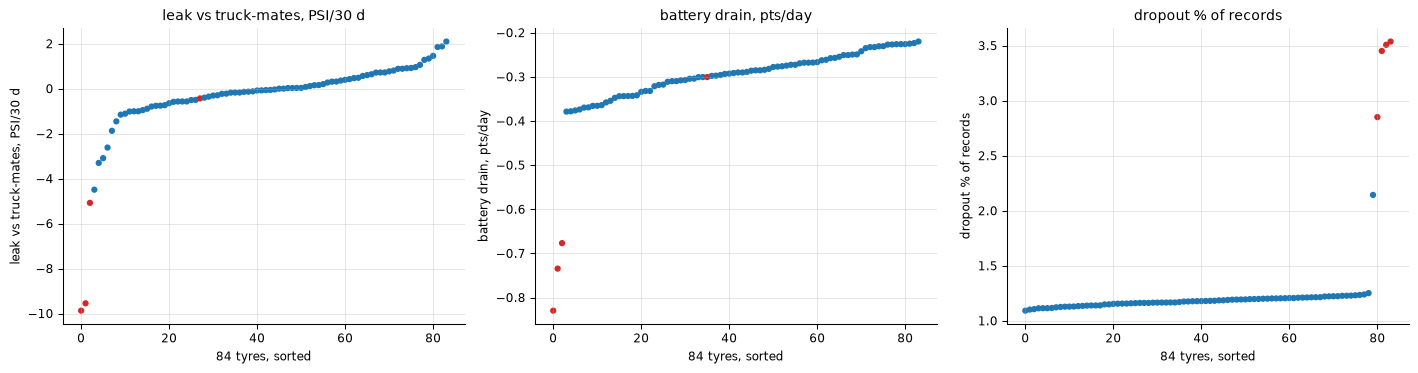

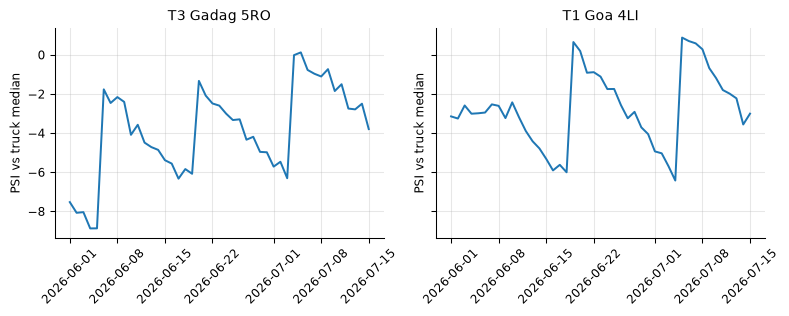

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, lab in zip(ax, ["leak_vs_trucks_psi_30d","battery_pts_per_day","dropout_%"], ["leak vs truck-mates, PSI/30 d","battery drain, pts/day","dropout % of records"]):
    y = WATCH[col]; a.scatter(range(len(y)), y.sort_values().values, s=14, c=["C3" if f else "C0" for f in WATCH.loc[y.sort_values().index, "n_flags"] > 0])
    a.set_ylabel(lab); a.set_xlabel("84 tyres, sorted"); a.set_title(lab)
plt.tight_layout(); plt.show()

# trajectories of the flagged tyres against their truck median
fl = [(a, b) for (a, b) in show.index[show.flag_leak]]
fig, axs = plt.subplots(1, len(fl), figsize=(4.2*len(fl), 3.4), sharey=True)
for a, (v_, s) in zip(np.atleast_1d(axs), fl):
    a.plot(R.loc[(v_, s)].index, R.loc[(v_, s)].values); a.set_title(f"{NAME[v_]} {s}"); a.set_ylabel("PSI vs truck median"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Finding 6 — a short, actionable list.** Out of 84 tyres, a few stand out on **leak, battery and dropout at the same time**; the overlap is itself evidence that the leak figures are real and not a sensor artefact:

* **T1 (Goa) 4LI** and **T3 (Gadag) 5RO** lose ~10 PSI/month *more* than their truck-mates (3 times the manufacturers' allowance) **and** drain their batteries ~2.5× the fleet rate **and** drop out ~3× as often; **T2 (Karwar) 3LO** has the same battery/dropout signature with a ~5 PSI/month excess. T1 4LI got a single-tyre top-up on 4 Jul (someone noticed) and is already drifting down again; T3 5RO is ~14 PSI under the card on top of the Hubballi hot-fill. **These are the candidates for "one alarm, one tyre"** — inspect valve, bead and sensor seal.
* **T5 (Shivamogga) 2RO sensor is at 1% battery** and dropping out more each week (2.9% of records over the period, ~6% by July): effectively gone within days, leaving that tyre blind.
* Fleet-typical battery drain is ~0.3 pts/day, which would empty a sensor in about a year — far from "3–4 years". The vendor's "normal for the first batch" is not supported by this rate, **but six weeks of a linear fit cannot establish a discharge curve**; ask TyreSense for one.
* **Caveat that matters for acting on the leak numbers:** I can't tell from TPMS alone whether the *tyre* or the *valve/sensor* leaks. A soap-and-water test on the valve and sensor seal at the next service separates them.

*Confidence:* high that these tyres deviate from their neighbours; moderate on the monthly rates (short window, depot top-ups interrupt the series).

## 7. A better alert: one tyre, with notice — and an honest test of it

**What the manager asked for:** *"one alarm, one tyre, one day's notice."* Two rules follow from the physics; both work on temperature-referred pressure compared with the truck's own other tyres, so thermal events and truck-wide depot actions cancel:

* **Fast-loss rule:** a tyre ≥4 PSI below *its own previous 6 hours* **and** ≥4 PSI worse than the median tyre's change on that truck, sustained 30 minutes.
* **Slow-leak rule:** nightly gap-to-truck-median falls faster than 6 PSI/month (2× the manufacturers' allowance) — the Section 6 list.

**Backtest, with its limits stated up front:** one real failure (n=1), one truck, six weeks. This is not a validation of detection performance; it shows what the rule does on the failure and how noisy it is on the other 83 tyres.

In [26]:
def fast_loss(PCt, drop=4.0, bins=3, base_bins=36):
    base = PCt.shift(1).rolling(base_bins, min_periods=18).median()
    d = base - PCt
    rel = d.sub(d.median(axis=1), axis=0)                         # remove whatever the whole truck did (fill, release, compensation error)
    flag = (rel >= drop).astype(float).where(PCt.notna())
    return rel, flag.rolling(bins).min() == 1

FAST = pd.DataFrame(False, index=PC.index, columns=PC.columns)
alerts = []
for v_ in VEH_ORDER:
    cols = [c for c in PC.columns if c[0]==v_]
    rel, sus = fast_loss(PC[cols].droplevel(0, axis=1))
    FAST.loc[:, cols] = sus.values
    for s_ in sus.columns:
        on = sus[s_] & ~sus[s_].shift(fill_value=False); last = None
        for t in on.index[on]:
            if last is None or t - last > pd.Timedelta("12h"):
                alerts.append((NAME[v_], s_, t, rel.loc[t, s_])); last = t
AL = pd.DataFrame(alerts, columns=["truck","tyre","alert_time","loss_vs_truck_PSI"])
print(f"Fast-loss alerts over 45 days x 84 tyres: {len(AL)}")
display(AL)

Fast-loss alerts over 45 days x 84 tyres: 4


,truck,tyre,alert_time,loss_vs_truck_PSI
0,T2 Karwar,5RI,2026-07-11 03:40:00,9.794389
1,T3 Gadag,5RI,2026-06-05 16:10:00,4.721453
2,T5 Shivamogga,5RI,2026-06-08 16:40:00,4.321053
3,T5 Shivamogga,5RO,2026-06-08 16:10:00,4.050955


In [27]:
# Alert load of every rule family, whole fleet, 45 days (3,780 tyre-days)
RULES2 = dict(RULES); RULES2["D. fast-loss + peer rule (this notebook)"] = FAST
LT2 = pd.concat([load_table(F, n) for n, F in RULES2.items()])
summary = LT2.groupby("rule").agg(tyre_days_alarmed=("tyre_days_alarmed_of_630","sum"), days_with_10plus_tyres_at_once=("days_with_10+_tyres_at_once","sum")).rename(index=lambda x: x)
summary["share_of_3780_tyre_days"] = (summary.tyre_days_alarmed/3780).round(3)
summary

,tyre_days_alarmed,days_with_10plus_tyres_at_once,share_of_3780_tyre_days
rule,,,
"A. fixed LOW, raw PSI < 90% of card",1254,80,0.332
"B. RAPID FALL, raw PSI down >= 8 in 30 min",711,30,0.188
"C. fixed LOW, temperature-referred PSI",1420,87,0.376
D. fast-loss + peer rule (this notebook),4,0,0.001


**Finding 7 — what the backtest does and does not show.**

* The fast-loss rule **fires on T2 5RI at 03:40 on 11 Jul** (20–25 minutes after the first deviation, ~8½ hours before the roadside stop). Over 45 days × 84 tyres it fires **three more times**, all on the afternoons the depots released air from hot tyres (T3 on 5 Jun, T5 on 8 Jun). Those are *real* pressure losses, caused by people rather than by a fault, and a deployed system could suppress them by recognising a truck-wide depot session (or simply by fixing the cold-fill rule). I have no other false alarms to report, but the sample is small.
* **Alert load over 45 days (3,780 tyre-days):** A (fixed low, raw) alarms on 1,254 tyre-days (33%); B (rapid fall, raw) on 711 (19%); C (fixed low, referred) on 1,420 (38%); the peer fast-loss rule D on **4 tyre-days in the whole fleet**. That is the difference between "fourteen alarms every afternoon" and "one alarm, one tyre".
* **Out-of-sample caveat:** I chose D's thresholds (4 PSI, 30 min, 6 h baseline) after looking at this failure and at the noise, so D's near-zero alert count is partly tuned to this dataset. It is a design proposal with one confirming case, not a validated detector.
* **"One day's notice" is not available for sudden failures.** For *slow* leaks (Section 6) it is: at the measured rates the listed tyres cross −15% of the card in weeks. For a sudden puncture like 11 Jul the achievable notice is **hours**; the value is routing the alert to the driver immediately.
* **What this cannot show:** detection rate. One failure, no failures elsewhere, six weeks. Do not quote a recall or a false-alarm rate with confidence.

## 8. Tread depth: what the inspection sheets can and cannot say

**Reasoning.** Tread loss is slow (mm per 1000 km), so any claim needs (a) the same tyre measured twice, (b) kilometres run in between, (c) a gauge reading more precisely than the change. The pack has two inspections for **one** truck (T1), one for T2, T3 and T4, none for T5 and T6 (the manager said as much).

In [28]:
nsd["side"] = np.where(nsd.Position.str[0]=="C", "L", "R")                        # C=left, D=right (verified by serial in Section 1)
one = nsd[nsd.Date.isin(pd.to_datetime(["2026-06-10","2026-06-30","2026-07-08","2026-07-09"]))]
LR = one.pivot_table(index=["Vehicle","axle"], columns="side", values="mean_nsd"); LR["R_minus_L_mm"] = LR.R - LR.L
print(f"Right-minus-left tread on the same axle, first inspection of each truck: right is deeper on {(LR.R_minus_L_mm>0).sum()} of {len(LR)} axles; median {LR.R_minus_L_mm.median():+.2f} mm")
print(LR.R_minus_L_mm.unstack().rename(index=NAME).round(1).to_string())

# T1 two inspections: wear per tyre by serial (follows the 28 Jun rotation), per 1000 km from the odometer log
k_between = km[(km.Vehicle=="KA25AB4471")&(km.Date>"2026-06-10")&(km.Date<="2026-07-14")]["KM Run"].sum()
a = nsd[(nsd.Vehicle=="KA25AB4471")&(nsd.Date=="2026-06-10")].set_index("Tyre Serial")
b2 = nsd[(nsd.Vehicle=="KA25AB4471")&(nsd.Date=="2026-07-14")].set_index("Tyre Serial")
wr = pd.DataFrame({"side_before": a.side, "tread_10Jun": a.mean_nsd, "tread_14Jul": b2.mean_nsd}); wr["loss_mm"] = wr.tread_10Jun - wr.tread_14Jul
wr["mm_per_1000km"] = wr.loss_mm / k_between * 1000
print(f"\nT1 km between the two inspections (11 Jun-14 Jul incl.): {k_between} (+/- one day's run)")
print(wr.groupby("side_before").agg(tyres=("loss_mm","size"), mean_loss_mm=("loss_mm","mean"), mm_per_1000km=("mm_per_1000km","mean")).round(2))
sc = nsd.assign(shoulder_minus_centre=(nsd["NSD Outer"]+nsd["NSD Inner"])/2 - nsd["NSD Centre"]).shoulder_minus_centre
print(f"\nShoulder-minus-centre tread over all {len(nsd)} readings: mean {sc.mean():+.2f} mm, sd {sc.std():.2f}, range {sc.min():+.2f}..{sc.max():+.2f}  (gauge resolution 0.1 mm)")

Right-minus-left tread on the same axle, first inspection of each truck: right is deeper on 20 of 20 axles; median +2.59 mm
axle        F1   F2   F3   R1   R2
Vehicle                           
T3 Gadag   3.8  4.1  3.8  2.7  3.7
T1 Goa     1.5  2.5  2.4  1.4  2.0
T2 Karwar  3.6  5.5  4.7  2.6  5.7
T4 City    1.2  1.8  2.3  1.6  2.0

T1 km between the two inspections (11 Jun-14 Jul incl.): 5074 (+/- one day's run)
             tyres  mean_loss_mm  mm_per_1000km
side_before                                    
L                7          0.77           0.15
R                7          0.42           0.08

Shoulder-minus-centre tread over all 70 readings: mean +0.02 mm, sd 0.11, range -0.25..+0.25  (gauge resolution 0.1 mm)


**Finding 8 — what can be said, and what cannot.**

* **Left tyres are more worn than right tyres on every axle of every inspected truck** (20 of 20 axle comparisons; median 2.6 mm deeper on the right). On T1, the only truck with two readings, **left-side tyres lost tread about twice as fast as right-side ones** (~0.15 vs ~0.08 mm per 1000 km). The manager rotated one pair on T1 "because one was wearing on the shoulder" — this says the asymmetry is fleet-wide, not one tyre. A hypothesis consistent with left-hand traffic is that left wheels run at the road edge/camber, but the pack cannot test it.
* **No under- or over-inflation wear pattern yet:** shoulder-vs-centre tread differs by sd 0.11 mm, max 0.25 mm, against a 0.1 mm gauge resolution. T3, 15% under-inflated for weeks, shows nothing — six weeks is too short; do not read this as "under-inflation is harmless".
* **T1 wear is slow** (0.07–0.16 mm per 1000 km; ~0.4–0.8 mm in 34 days): the gauge (0.1 mm) and ±1-day km uncertainty limit this to ±30%. At T1's ~146 km/day, tyres at ~10–14 mm have well over a year of tread.
* **"Are the Hubballi roads eating my tyres?" — the pack cannot answer it.** No Hubballi truck has two inspections; tyre ages, brands and fitting dates differ by position; the km before fitting is unknown. What would answer it: a second inspection of T3 and T4 after ≥5,000 km, compared per-tyre with T1's rate (same brand/pattern where possible). Pressure leakage (Section 4) is *not* higher at Hubballi, but wear is a different question.
* **Reading identical at three points:** two rows (T2 5RI/5RO) show 15.9/15.9/15.9 and 12.0/12.0/12.0; handle with care (Section 5).

## 9. The ghat: what the temperature trace can say about braking

**Reasoning.** On a long descent the vehicle's brakes absorb its potential energy; brake drums conduct heat into the wheels, and the valve-stem sensor warms. If the brakes are weak the driver brakes harder and longer, so drive-axle tyre temperature on descents should drift **upward** over time (more so after relining in May). The sensor is a weak proxy, but it is the only brake-adjacent signal in the pack.

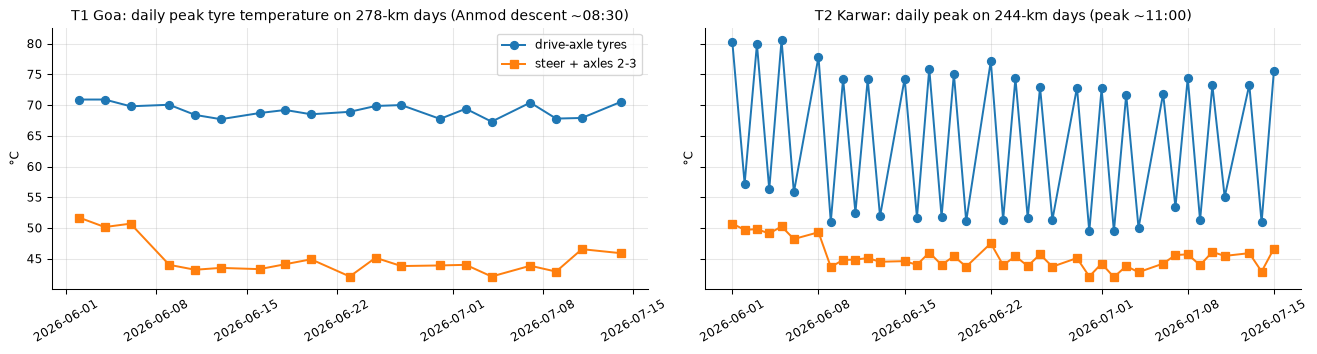

T1 drive-axle descent peak: mean 69.2 °C, range 67.3-70.9;  trend -0.8 °C per 30 d (p=0.19, n=19)
T2 peaks alternate: hot days mean 75.1 | cool days mean 52.3 | 11 Jul (failure day) peak 55.0


In [29]:
def daily_peaks(v_):
    x = TMP.loc[:, [c for c in TMP.columns if c[0]==v_]].droplevel(0, axis=1)
    out = []
    for d, g in x.groupby(x.index.floor("D")):
        kmr = km[(km.Vehicle==v_)&(km.Date==d)]["KM Run"]
        if not len(kmr) or kmr.iloc[0] < 150: continue
        pk = g.max(); tpk = g.max(axis=1).idxmax()
        out.append(dict(day=d, km=kmr.iloc[0], drive_axles=max(pk[["4LI","4LO","4RI","4RO","5LI","5LO","5RI","5RO"]]), steer_and_ax23=max(pk[["1LO","1RO","2LO","2RO","3LO","3RO"]]),
                        t_peak=tpk.strftime("%H:%M")))
    return pd.DataFrame(out).set_index("day")
H1, H2 = daily_peaks("KA25AB4471"), daily_peaks("KA25AC1182")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
ax[0].plot(H1.drive_axles, "o-", label="drive-axle tyres"); ax[0].plot(H1.steer_and_ax23, "s-", label="steer + axles 2-3"); ax[0].set_title("T1 Goa: daily peak tyre temperature on 278-km days (Anmod descent ~08:30)"); ax[0].legend()
ax[1].plot(H2.drive_axles, "o-", label="drive-axle tyres"); ax[1].plot(H2.steer_and_ax23, "s-", label="steer + axles 2-3"); ax[1].set_title("T2 Karwar: daily peak on 244-km days (peak ~11:00)")
for a in ax: a.set_ylabel("°C"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
sl = stats.linregress((H1.index - H1.index[0]).days, H1.drive_axles)
print(f"T1 drive-axle descent peak: mean {H1.drive_axles.mean():.1f} °C, range {H1.drive_axles.min():.1f}-{H1.drive_axles.max():.1f};  trend {sl.slope*30:+.1f} °C per 30 d (p={sl.pvalue:.2f}, n={len(H1)})")
print("T2 peaks alternate: hot days mean", round(H2[H2.drive_axles>65].drive_axles.mean(),1), "| cool days mean", round(H2[H2.drive_axles<65].drive_axles.mean(),1), "| 11 Jul (failure day) peak", round(H2.loc['2026-07-11'].drive_axles,1))

**Finding 9 — heat is real and large, but the data do not show brake deterioration.**

* On every Goa day the drive-axle tyres hit ~67–71 °C around 08:30 (the Anmod descent) while the steer and axles 2–3 stay ~42–50 °C: brake heat reaching the drive wheels. Raw pressure peaks at ~130 PSI.
* **No upward trend over six weeks** (−0.8 °C per 30 days, p = 0.19, n = 19 descents). The driver's "pedal going soft" is a *feel* and may be real (fade within a descent), but a daily peak temperature at the valve stem cannot test it; the sensor sees heat at the stem, not at the lining.
* T2 (Karwar, heavy both ways) runs *hotter* than T1 on alternate days (mean 75 °C vs 69 °C) and cooler on the other days (mean 52 °C), yet nobody complains of its brakes. The failure day (11 Jul) was a *cool* day (peak 55 °C), so **heat is not an obvious cause of the failure**.
* **What the pack cannot say:** descent speed, gear, brake-pedal pressure, load. The manager says the box has speed and altitude channels that are "not in what they send us". Obtaining them from TyreSense is the way to answer the ghat question properly.

## 10. The manager's account against the data

Treated "as any single informant: useful, partial, and occasionally wrong".

| What he said | Verdict | Evidence |
|---|---|---|
| Hubballi fills in the afternoon, Belagavi first thing at six | **Confirmed** (Hubballi later than he said) | Belagavi sessions ~06:00–06:30; Hubballi ~15:30–16:00, not "around one" (§4) |
| "Hubballi readings are always low… I think they leak more because of bad roads" | **Not supported** | Cold readings 7–10 PSI under, explained by hot fills/releases; leak rates equal across depots (p=0.24) (§4) |
| "Gauge probably fine, never compared with TyreSense" | **Gauge and TPMS agree** within ~1 PSI at the moment of filling | 188 tyre-sessions: mean +0.1, sd 1.2 PSI (§4) |
| Each truck is done "once in ten–fifteen days" | **Overstated** | Truck-wide sessions every ~2–5 weeks; plus a few single-tyre top-ups (§4) |
| "Every afternoon in June the Goa truck's alerts… all fourteen at once" | **Partly** | 10 of 30 June days (17 of 45 overall) show an all-tyre cooling event; cause is thermal (§3) |
| "Fourteen tyres do not puncture together" | **Correct** | Common-cause cooling on 4–6 trucks at once (§3) |
| "Rain came early, second week of June… Belagavi mostly dry" | **Consistent for the start date; the "dry Belagavi" part cannot be tested** | First synchronous cooling 10–11 Jun, also on Belagavi/Hubballi trucks; no weather data (§3) |
| Swapped a pair "on the Goa truck, no wait, maybe the Karwar one… check the register" | **It was the Goa truck (T1), Sunday 28 Jun** | Register, inspection sheet and a sensor-battery swap in the data all agree (§1) |
| Inspector: Goa twice, others once, never Mangaluru (T5) or Vijayapura (T6) | **Confirmed** | T1 ×2; T2, T3, T4 ×1; T5, T6 none (§8) |
| "One blew on the Karwar road in July… nobody saw it coming" | **Nobody did; the sensor did** | Loss visible from ~03:15, 8 h 56 min before the stop (§5) |
| Driver felt the truck "heavy on one side"; "by two o'clock it was finished" | **Consistent** | Inner twin 20–40 PSI down and invisible from outside; last reading 14:19 (§5) |
| Sensor batteries "3–4 years… some low already; TyreSense says normal" | **Not supported by the rate, but not disproved** | Fleet median ~0.29 pts/day; four sensors 2–3× worse; T5 2RO at 1% (§6) |
| "The kilometre log is the most honest number; the GPS I don't know" | **Both right** | Log chains perfectly and matches GPS within 2–6%; "map jumps" come from T1/T2 GPS holes (§1) |
| Goa brakes "going soft by the bottom" of Anmod | **Untestable** | No brake/speed data; drive-axle temperature shows no trend (§9) |
| Shivamogga truck did one Mangaluru run in the first week of July | **Confirmed** | GPS south of 13.3°N on 5–6 Jul; 391 km on 6 Jul |
| Goa truck "three times a week" down the ghat | **Confirmed** | 278-km days are Tue/Thu/Sat; 19 in 45 days |

## 11. The five questions I would put to Mr Vijayan, in order of importance

1. **At Hubballi, exactly when and on what reading do the boys add or release air — and do they ever let air out when a hot tyre reads above the card?**
   *Why:* §4 shows hot fills and two hot releases (T4 4 Jun, T3 5 Jun) leaving T3/T4/T5 7–17 PSI under standard when cold. *What I'd do with it:* if confirmed, replace the routine with "cold only, or add a hot-correction card", re-check the three trucks next morning, and drop the "Hubballi leaks" idea that is hiding the real cause.
2. **What alert rules and thresholds did TyreSense configure, who receives them (app, SMS, whom?), and did anyone get an alert on the Karwar truck between 03:15 and 12:00 on 11 July?**
   *Why:* the pack contains no alert rules; I can only show what a rule *would* have done. This tells us whether the failure alert never existed or was ignored among the thermal noise. *Action:* route a single-tyre relative-pressure alert to the driver and set expectations on what it means.
3. **For the failed tyre (serial …5RI-0242): when was it fitted, new or retread, which brand, and what did the casing show (nail, valve, bead, sidewall)?**
   *Why:* the register overwrote it, and the inspection sheet shows it 3.9 mm deeper than its twin with identical readings at all three points. *Action:* decide whether a twin-matching rule (tread within ~2–3 mm) is warranted, and re-measure the other twins.
4. **Roughly what does each truck carry, by direction (empty / part / full), and is the Goa truck really often empty on the way back?**
   *Why:* the card is for *rated* axle load; drive-axle heat, pressure need and the Goa/Karwar difference cannot be separated from load with this pack. *Action:* add a three-level load tick to the clerk's daily km log (costs nothing) and revisit pressure by load.
5. **Can Rajan inspect all six trucks again at ≥5,000 km intervals, and have any tyres been rotated or replaced since 15 July?**
   *Why:* only T1 has a wear rate; Hubballi roads, left/right wear and the 12-month sensor-battery question all need a second reading. *Action:* a second set on T3/T4 and a first on T5/T6 answers "are the Hubballi roads eating my tyres" with data instead of belief.

## 12. What this pack cannot answer

* **Whether Hubballi roads wear tyres faster** — one inspection per Hubballi truck, no km history before fitting.
* **What the vendor's alerts do** — rules and thresholds are not provided; my statements about them are inference from the manager's description.
* **Whether the temperature is gas or stem temperature** — hypothesis only (§2).
* **Load, speed, altitude, brake state, weather** — not recorded; the manager says the box has speed/altitude but they are not exported.
* **Why 5RI failed** — fast leak, cause unknown; the casing and the tyre's history are not in the pack.
* **Whether failures generally have a slow precursor** — one failure, silent on the rest.
* **Whether the depot gauge is accurate in absolute terms** — it agrees with TPMS, but both could share an offset; a calibrated reference gauge on one truck would settle it.
* **Sensor battery life** — six weeks of a roughly linear fit.

## 13. Distrust inventory — what in the pack is wrong, duplicated, inconsistent or misleading, and what I did

| # | Item | Why it matters | What I did |
|---|---|---|---|
| 1 | **June/July exports overlap by 12 h** (2,869 duplicate rows) | Double-counting at the boundary | Verified 100% identical; de-duplicated on (vehicle, time) |
| 2 | **T1's July file labels every row `KA25B4471`** (27,082 rows) | A join on the Vehicle column drops T1's July | Keyed on the file name |
| 3 | **Data Dictionary reverses C/D sides** ("C = co-driver side (right)" vs its own "CF1 = front left") | Flips every left/right tread comparison | Resolved with tyre-serial L/R (34/34 and 34/34) and the manager's account: **C = left, D = right** |
| 4 | **Register is a 15 Jul snapshot**: the failed tyre's record (brand, mount date) is overwritten by its replacement | Lost history of the one tyre that matters | Noted; added to Question 3 |
| 5 | **Slot ≠ tyre**: T1 3LO/3RO swapped on 28 Jun, serials cross | Per-slot trends silently change tyre mid-series | Detected via battery swap; rebuilt sensor battery per sensor; used serials for wear |
| 6 | **Raw PSI is not comparable with the spec** (cold) and swings ~14 PSI/day with temperature | Fixed-threshold alarms mix air loss with heat | Referred all pressures to 25 °C with an empirical 0.71 PSI/°C |
| 7 | **Sensor temperature responds ~1.9× less than a gas would** | Textbook compensation under-corrects by about half | Calibrated on parked (0-km) days instead of assuming the gas law |
| 8 | **Rows are unevenly spaced** (18 s moving, 2 min parked) | Row averages over-weight driving | All summaries use fixed 5–10 min bins |
| 9 | **GPS missing ~15% on T1/T2 (daytime)** | Distance from GPS and "map jumps" | Bridged gaps with a jump filter; relied on the odometer for distance |
| 10 | **`Avg Battery` is the mean of sensors that *reported*** | Moves when a sensor drops out | Not used; per-slot battery instead |
| 11 | **`GPS Time` is in IST**, within 3 s of receiver time (real GPS time is UTC) | Vendor converted it; low risk | Verified consistent; no action |
| 12 | **Inspection coverage is thin**: T5, T6 never; T2/T3/T4 once; T1 twice | No wear rate except T1 | Used only what is defensible; said so (§8) |
| 13 | **T2 5RI/5RO readings are identical at all three gauge points** (15.9 and 12.0), unlike all other tyres | Possible careless entry on the failed tyre | Flagged; treated the 3.9 mm mismatch as a question, not a finding |
| 14 | **Spec card is one set of pressures "regardless of make" at rated axle load**; no load records | May not fit actual loads (e.g. empty Goa returns) | Used it as given; Question 4 |
| 15 | **Policy vs practice**: spec says check weekly with a calibrated gauge; manager says each truck every 10–15 days (data: 2–5 weeks) | Procedure not followed | Reported in §4/§10 |
| 16 | **Manager's account has memory errors** (rotation truck; frequency; "Hubballi leaks"; "every afternoon") | Single informant | Checked each against the data (§10) |
| 17 | **Brief says the failure came with "no warning"** | The data show 8 h 56 min of warning | §5 |
| 18 | **Cooling events at the same 10-minute bin across trucks 100+ km apart** | Real showers are patchier; possible shared pipeline component | Reported as consistent with a regional front but not proven (§3) |

## 14. Method notes: things I believed early and had to drop

* *"T6 is over-inflated by ~10 PSI."* — An artefact of looking at raw (hot) medians; once referred to 25 °C, T6 sits on the card.
* *"A fixed 90% low threshold explains the Goa afternoon alarms."* — Tested and **false** (that rule is silent on Goa); a rapid-fall rule reproduces them. The manager's own word was "dropping".
* *"The T3/T4 step down on 5–6 Jun is a sensor glitch."* — It is a hot release at 15:30–16:10, the opposite of a fill, at the same hour as the fills.
* *"Leak rates differ by depot."* — They don't (p=0.24); the outliers are individual tyres.
* *"The textbook gas law will compensate temperature."* — It under-corrects by about half for this sensor; I calibrated empirically.
* I did **not** treat the vendor's thresholds as known, the weather as known, or the TPMS temperature as the gas temperature.